In [1]:
%matplotlib inline
# %matplotlib qt
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time
import matplotlib
from astropy.coordinates import SkyCoord

from spysii.utils import format_matplotlib_to_mnras

In [2]:
results = dict()

In [4]:
# Let's assume the moon NSB is equivalent to a 6th mag star (not sure at all about this number...)
moon_magnitude_equivalent = 6.

n_simulations = 10

times = ['2021-05-14T22:00:00',
         '2021-05-14T23:00:00',
         '2021-05-15T00:10:00',
         '2021-05-15T01:00:00', 
         '2021-05-15T02:00:00', 
         '2021-05-15T03:00:00', 
         '2021-05-15T04:00:00']
time_array = Time(times, format='isot', scale='utc')

# individual_observing_times = [5., 10., 20.]
individual_observing_times = [20.]
magnitudes = np.arange(0, 6.5, 0.75)
telescopes = ["MAGIC", "MAGIC-LST", "MAGIC-4LST"]
# telescopes = ["MAGIC-CTA-N"]
for tel in telescopes:
    print("-------")
    print("-------")
    print("Simulating observations with the following array: {}".format(tel))
    print("- simulations per magnitude: {}".format(n_simulations))
    sim_run = SimulateSiiRuns("zet Oph", zbc_norm=1., observatory_name=tel)
    results[tel] = dict()
    results[tel]['rel_error'] = []
    results[tel]['rel_error_unc'] = []
    for obs_time in individual_observing_times:

        resulting_rel_error = []
        resulting_rel_error_unc = []
        for mag in magnitudes:
            print("Computing relative error of gam Crv if it was a mag {} star".format(mag))
            fit_norms = []
            fit_theta = []
            fit_relative_err = []
            # Here we artifitially modify the magnitude of the star
            sim_run.target_b_mag = mag 

            for i in np.arange(0, n_simulations, 1):
        #         if i%100 == 0:
        #             print("{}/{}".format(i, n_simulations))
                sim_run.simulate_observations(time_array, run_duration=obs_time*u.min, 
                                              moon_to_star_ratio=2.512**(sim_run.target_b_mag - moon_magnitude_equivalent))
                sim_run.simulate_zbc_observations(time_array, run_duration=obs_time*u.min, 
                                                  moon_to_star_ratio=2.512**(sim_run.target_b_mag - moon_magnitude_equivalent))
                sim_run.fit_uniform_disc()
                fit_results = sim_run.uniform_disc_fit
                fit_theta.append(fit_results['theta'])
                fit_norms.append(fit_results['norm'])
                fit_relative_err.append(fit_results['theta_e']/fit_results['theta'])
                sim_run.reset()
            resulting_rel_error.append(np.average(fit_relative_err))
            resulting_rel_error_unc.append(np.std(fit_relative_err))
        results[tel]['rel_error'].append(resulting_rel_error)
        results[tel]['rel_error_unc'].append(resulting_rel_error_unc)

-------
-------
Simulating observations with the following array: MAGIC
- simulations per magnitude: 10
Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (249.28974606, -10.56709152)>
Closest star found within the JMDC is:
 -Star ids: HD149757 or ZET OPH
- Stellar diameter: 0.5
Computing relative error of gam Crv if it was a mag 0.0 star
Computing relative error of gam Crv if it was a mag 0.75 star
Computing relative error of gam Crv if it was a mag 1.5 star
Computing relative error of gam Crv if it was a mag 2.25 star
Computing relative error of gam Crv if it was a mag 3.0 star
Computing relative error of gam Crv if it was a mag 3.75 star
Computing relative error of gam Crv if it was a mag 4.5 star
Computing relative error of gam Crv if it was a mag 5.25 star
Computing relative error of gam Crv if it was a mag 6.0 star
-------
-------
Simulating observations with the following array: MAGIC-LST
- simulations per magnitude: 10
Found star with c.SkyCoord.from_na

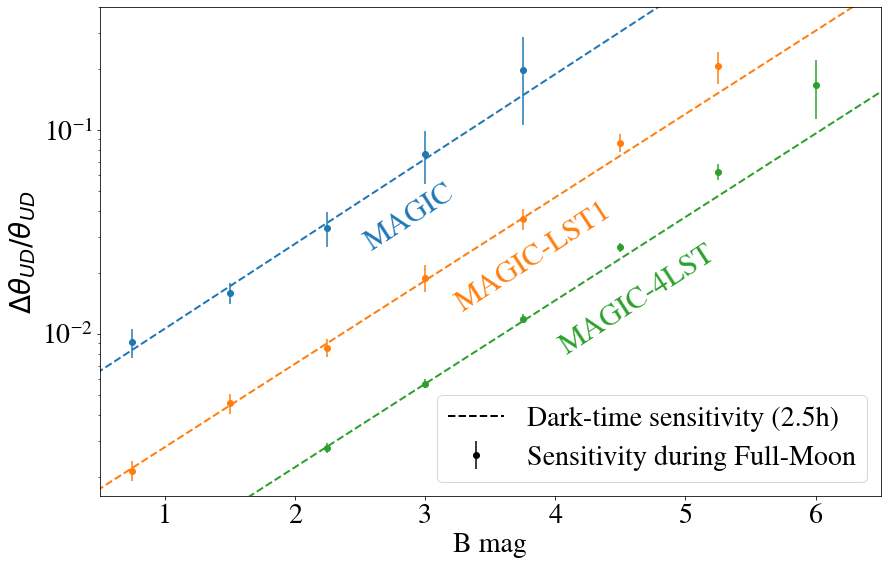

In [13]:
format_matplotlib_to_mnras(28)

from scipy.optimize import curve_fit

# plt.rc('font', family='Nimbus Roman')

# Function to calculate the power-law with constants a and b
def straight_line(x, a, b):
    return a*x + b

# font = {'family' : 'Nimbus Roman',
# #         'weight' : 'bold',
#         'size'   : 20}
# matplotlib.rc('font', **font)

f = plt.figure(figsize=(14, 9))
ax1 = f.add_subplot(111)

i=0
ax1.errorbar(magnitudes[0:6], results["MAGIC"]['rel_error'][i][0:6], 
             yerr=results["MAGIC"]['rel_error_unc'][i][0:6], fmt='o',
#              label="MAGIC: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)),
            )
ax1.errorbar(magnitudes[0:8], results["MAGIC-LST"]['rel_error'][i][0:8], 
             yerr=results["MAGIC-LST"]['rel_error_unc'][i][0:8], fmt='o',
#              label="MAGIC-LST1: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)),
            )
ax1.errorbar(magnitudes, results["MAGIC-4LST"]['rel_error'][i], 
             yerr=results["MAGIC-4LST"]['rel_error_unc'][i], fmt='o',
#              label="MAGIC-4LST: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)),
            )

# ax1.errorbar(magnitudes, results["MAGIC-CTA-N"]['rel_error'][i], 
#              yerr=results["MAGIC-CTA-N"]['rel_error_unc'][i], fmt='o',
# #              label="MAGIC-4LST: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)),
#             )


ax1.errorbar(magnitudes, np.array(results["MAGIC-4LST"]['rel_error'][i])*1e-6, 
             yerr=np.array(results["MAGIC-4LST"]['rel_error_unc'][i])*1e-6, fmt='o', color='black',
             label="Sensitivity during Full-Moon")


pars_magic, cov_magic = curve_fit(f=straight_line, xdata=magnitudes[0:5], ydata=np.log10(results["MAGIC"]['rel_error'][i][0:5]), p0=[1, 4.])
pars_lst, cov_lst = curve_fit(f=straight_line, xdata=magnitudes[0:5], ydata=np.log10(results["MAGIC-LST"]['rel_error'][i][0:5]), p0=[1, 4.])
pars_4lst, cov_4lst = curve_fit(f=straight_line, xdata=magnitudes[0:5], ydata=np.log10(results["MAGIC-4LST"]['rel_error'][i][0:5]), p0=[1, 4.])

ext_magnitudes = np.arange(0, 6.5+0.75, 0.75)
# Plot the fit data as an overlay on the scatter data
ax1.plot(ext_magnitudes, 10**straight_line(ext_magnitudes, *pars_magic), linestyle="--", linewidth=2, color="C0")
ax1.plot(ext_magnitudes, 10**straight_line(ext_magnitudes, *pars_lst), linestyle="--", linewidth=2, color="C1")
ax1.plot(ext_magnitudes, 10**straight_line(ext_magnitudes, *pars_4lst), linestyle="--", linewidth=2, color="C2")
ax1.plot(ext_magnitudes, np.zeros_like(ext_magnitudes), linestyle="--", linewidth=2, color="black", 
         label="Dark-time sensitivity (2.5h)")
    
ax1.xaxis.set_label_text('B mag', 
                         #fontsize=26
                        )
ax1.yaxis.set_label_text(r'$\Delta\theta_{UD} / \theta_{UD}$',
                         #, fontsize=26
                        )

ax1.text(2.5, 2.6e-2, 'MAGIC', color='C0', rotation="33", 
         fontsize=30
        )
ax1.text(3.2, 1.3e-2, 'MAGIC-LST1', color='C1', rotation="33", 
         fontsize=30
        )
ax1.text(4.0, 8e-3, 'MAGIC-4LST', color='C2', rotation="33", 
         fontsize=30
        )

ax1.set_yscale('log')
ax1.set_xlim([0.5, 6.5])
ax1.set_ylim([1.6e-3, 0.4])
ax1.legend()
f.savefig("sensitivity_simulation.pdf", bbox_inches='tight')

In [2]:
sim_run = SimulateSiiRuns("gam Crv", zbc_norm=1., observatory_name="MAGIC-LST")
sim_run.target_b_mag

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (183.95154504, -17.54193046)>
Closest star found within the JMDC is:
 -Star ids: HD106625 or GAM CRV
- Stellar diameter: 0.72


2.48

In [3]:
times = ['2021-07-01T22:00:00', 
         '2021-07-01T23:00:00', 
         '2021-07-02T00:00:00', 
         '2021-07-02T01:00:00', 
         '2021-07-02T02:00:00', 
         '2021-07-02T03:00:00']
time_array = Time(times, format='isot', scale='utc')
zbc_times = ['2021-07-01T22:30:00', 
             '2021-07-01T23:30:00']
zbc_time_array = Time(zbc_times, format='isot', scale='utc')

In [4]:
sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.simulate_zbc_observations(zbc_time_array, run_duration=10*u.min)

ERROR:root:The altitude of the source at the time 2021-07-02T00:00:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2021-07-02T00:01:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2021-07-02T00:02:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2021-07-02T00:03:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2021-07-02T00:04:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2021-07-02T00:05:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2021-07-02T00:06:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2021-07-02T00:07:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2021-07-02T00:08:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2021-07-02T00:09:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2021-07-02T01:00:00.000 is just too low.

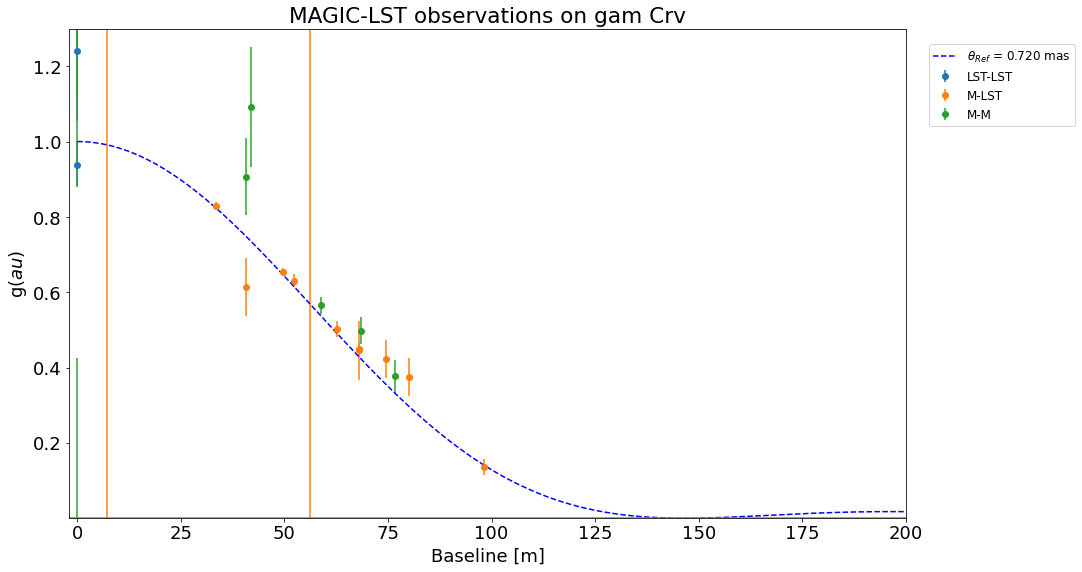

In [5]:
sim_run.plot_v2(set_log_yscale=False)
sim_run.f.savefig("test.png")

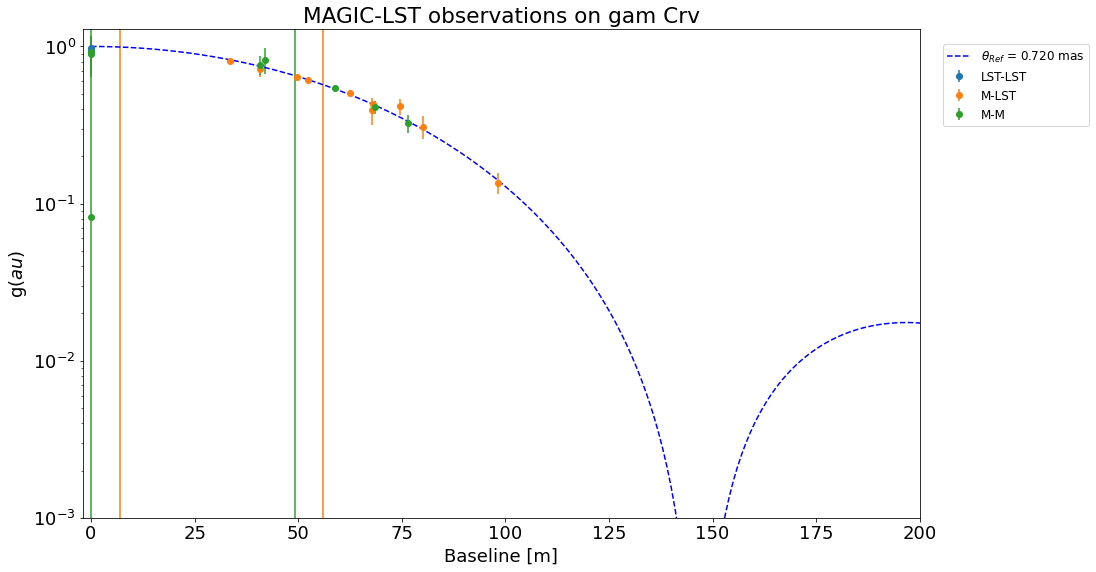

In [6]:
sim_run.plot_v2()

In [7]:
sim_run.fit_uniform_disc()

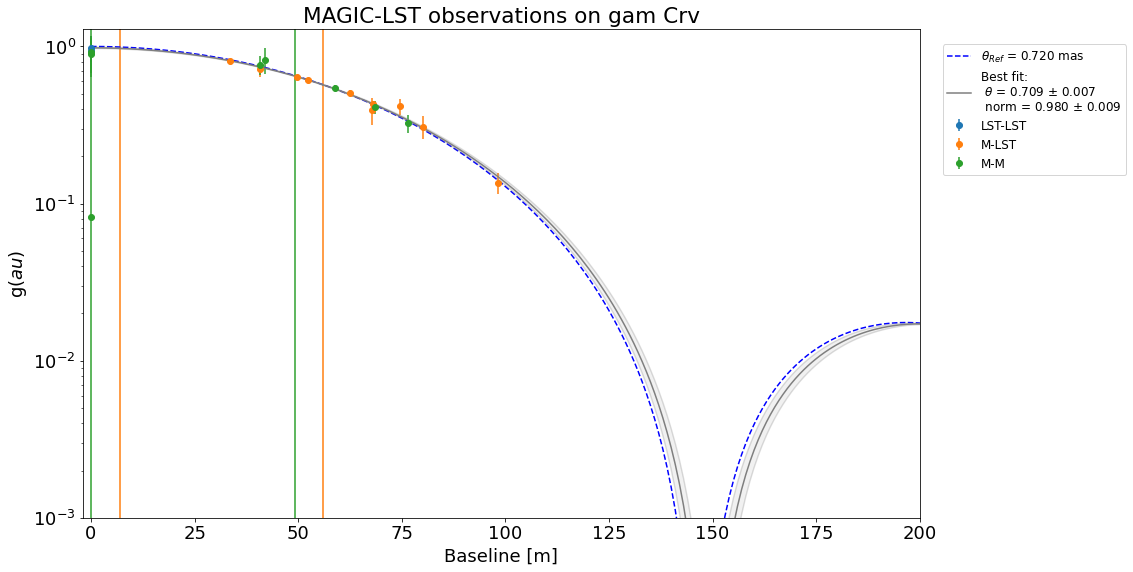

In [8]:
sim_run.plot_v2()

In [9]:
n_simulations = 50
times = ['2021-07-01T22:00:00', 
     '2021-07-01T23:00:00', 
     '2021-07-02T00:00:00', 
     '2021-07-02T01:00:00', 
     '2021-07-02T02:00:00', 
     '2021-07-02T03:00:00', 
     '2021-07-02T04:00:00']
time_array = Time(times, format='isot', scale='utc')

fit_norms = []
fit_theta = []
sim_run = SimulateSiiRuns("eta UMa", zbc_norm=1., observatory_name="MAGIC-LST")
for i in np.arange(0, n_simulations, 1):
    if i%100 == 0:
        print("{}/{}".format(i, n_simulations))
    sim_run.simulate_observations(time_array, run_duration=10*u.min)
    sim_run.fit_uniform_disc()
    fit_results = sim_run.uniform_disc_fit
    fit_theta.append(fit_results['theta'])
    fit_norms.append(fit_results['norm'])
    sim_run.reset()

Closest star found within the JMDC is:
 -Star ids: HD120315 or eta UMa
- Stellar diameter: 0.937
0/50


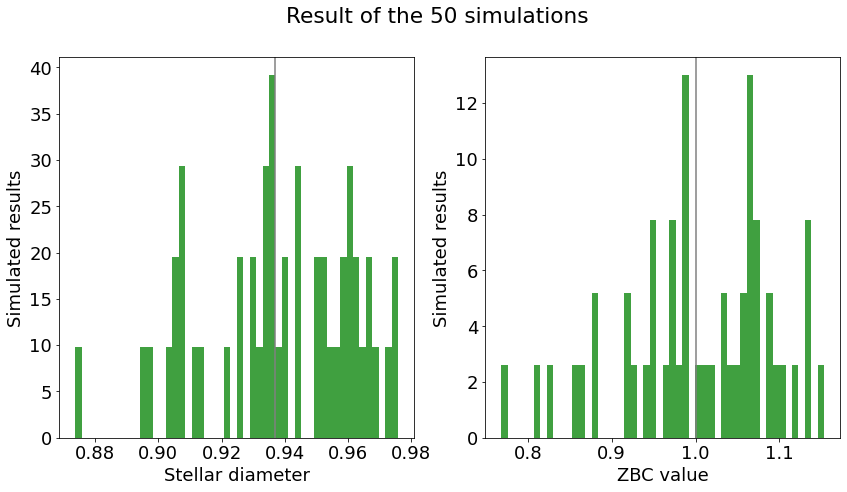

In [4]:
# the histogram of the data
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=[14, 7])
fig.suptitle('Result of the {} simulations'.format(n_simulations))
ax1.hist(fit_theta, 50, density=True, facecolor='g', alpha=0.75)
ax1.axvline(x=sim_run.stellar_diameter.to('mas').value, color='grey', linestyle='-')
ax1.yaxis.set_label_text('Simulated results')
ax1.xaxis.set_label_text('Stellar diameter')

ax2.hist(fit_norms, 50, density=True, facecolor='g', alpha=0.75)
ax2.axvline(x=sim_run.zbc_norm, color='grey', linestyle='-')
ax2.yaxis.set_label_text('Simulated results')
ax2.xaxis.set_label_text('ZBC value')
plt.show()


Simulation gam Crv
---------

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (183.95154504, -17.54193046)>
Closest star found within the JMDC is:
 -Star ids: HD106625 or GAM CRV
- Stellar diameter: 0.72


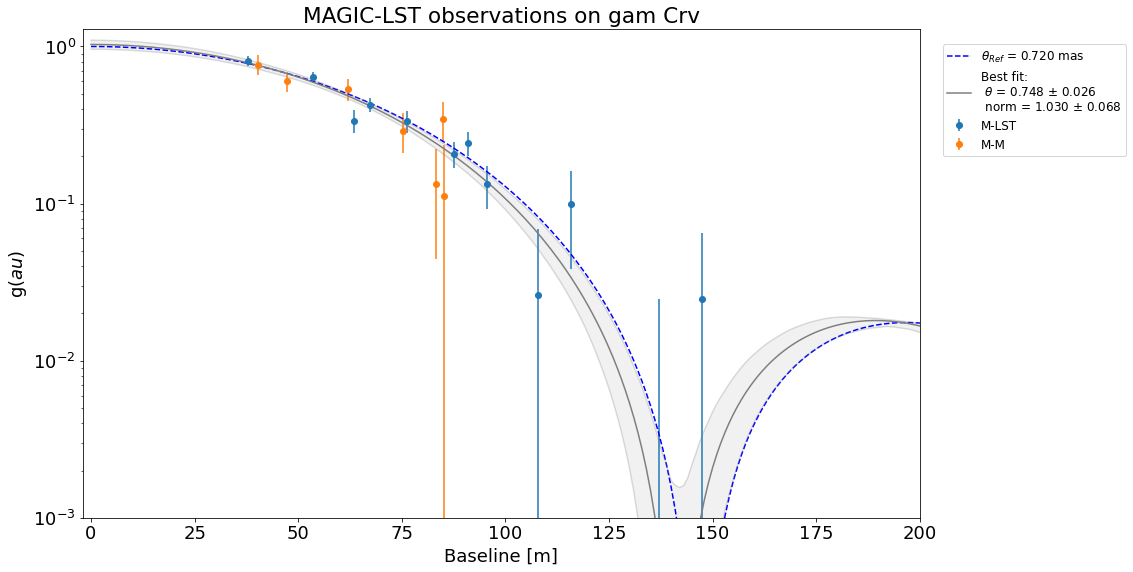

In [10]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("gam Crv", zbc_norm=1., observatory_name="MAGIC-LST")

times = ['2021-02-12T00:00:00',
         '2021-02-12T00:45:00',
         '2021-02-12T01:30:00',
         '2021-02-12T03:00:00', 
         '2021-02-12T04:30:00', 
         '2021-02-12T06:00:00', 
         '2021-02-12T07:30:00']
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min)
# sim_run.simulate_zbc_observations(zbc_time_array, run_duration=30*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (249.28974606, -10.56709152)>
Closest star found within the JMDC is:
 -Star ids: HD149757 or ZET OPH
- Stellar diameter: 0.5


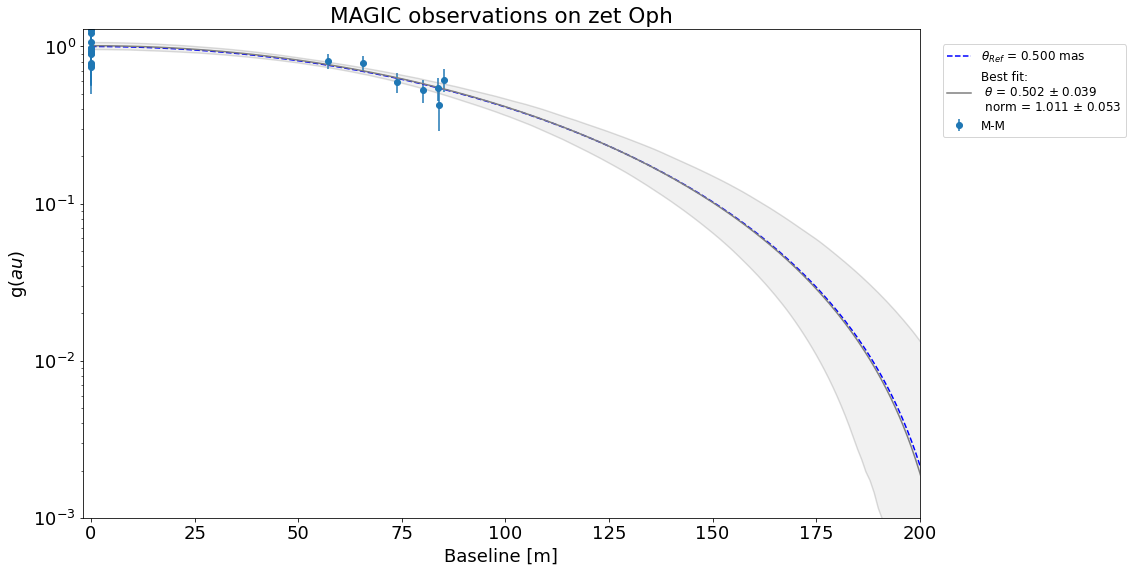

0.07724630197657138

In [11]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("zet Oph", zbc_norm=1., observatory_name="MAGIC")

times = ['2021-05-14T22:00:00',
         '2021-05-14T23:00:00',
         '2021-05-15T00:10:00',
         '2021-05-15T01:00:00', 
         '2021-05-15T02:00:00', 
         '2021-05-15T03:00:00', 
         '2021-05-15T04:00:00']
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.simulate_zbc_observations(time_array, run_duration=10*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']

Exploring how relative errors evolved with star brightness, fixing all parameters.

Closest star found within the JMDC is:
 -Star ids: HD36090 or S ORI
- Stellar diameter: 10.54


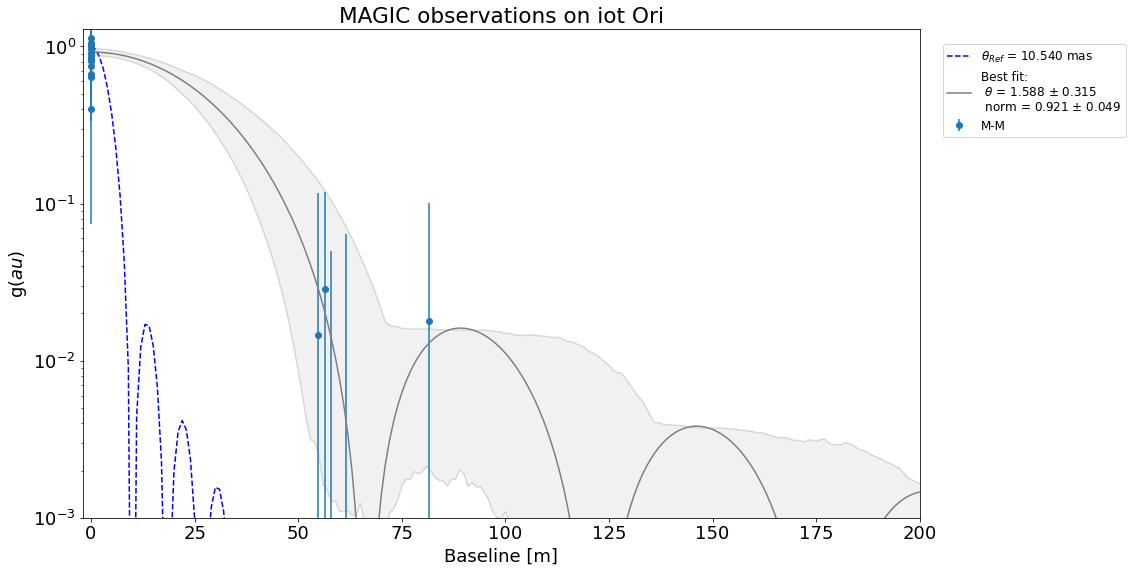

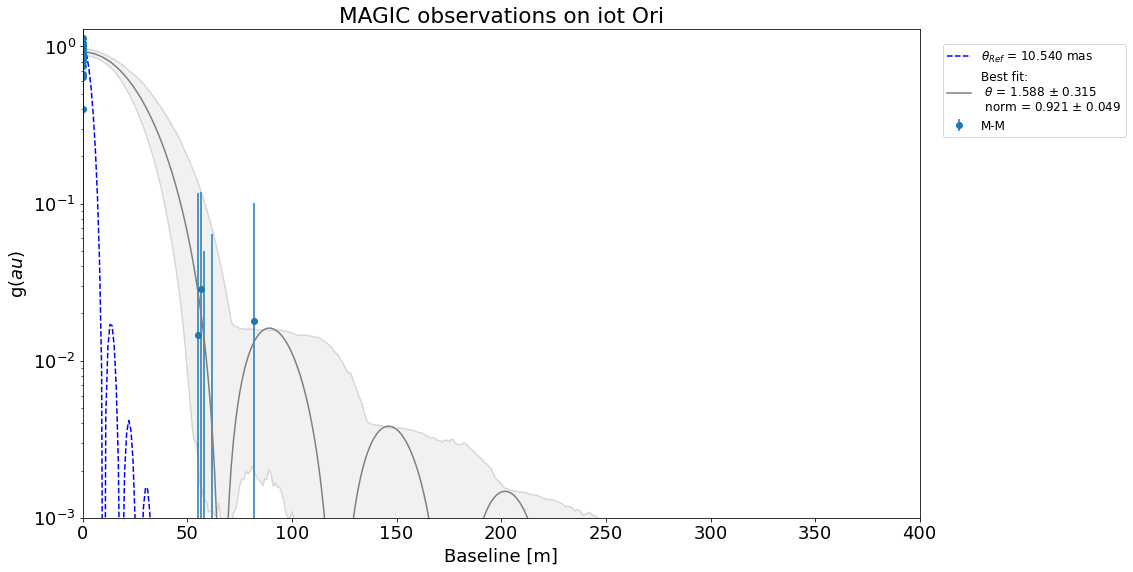

In [12]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("iot Ori", zbc_norm=1., observatory_name="MAGIC")

times = ['2022-02-12T20:00:00',
         '2022-02-12T21:00:00',
         '2022-02-12T22:00:00',
         '2022-02-12T23:00:00', 
         '2022-02-12T00:00:00', 
         '2022-02-12T01:00:00', 
         '2022-02-12T02:00:00']
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.simulate_zbc_observations(time_array, run_duration=10*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
sim_run.f.get_axes()[0].set_xlim([0, 400])
sim_run.f

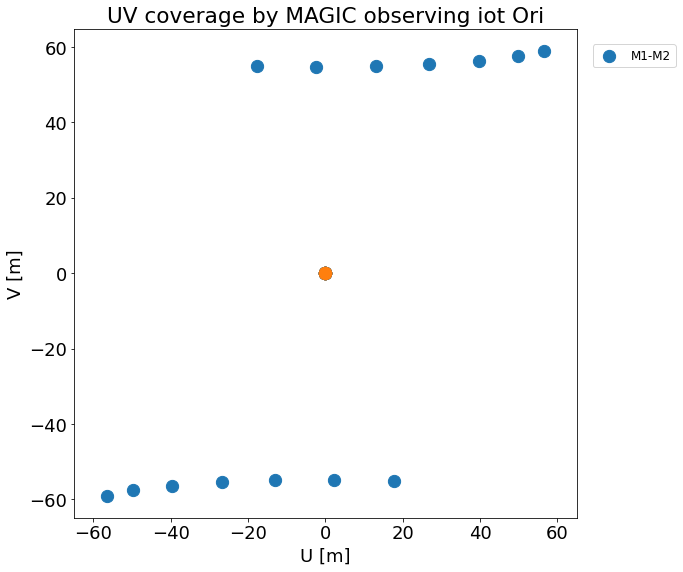

In [13]:
sim_run.plot_uv()

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (183.95154504, -17.54193046)>
Closest star found within the JMDC is:
 -Star ids: HD106625 or GAM CRV
- Stellar diameter: 0.72


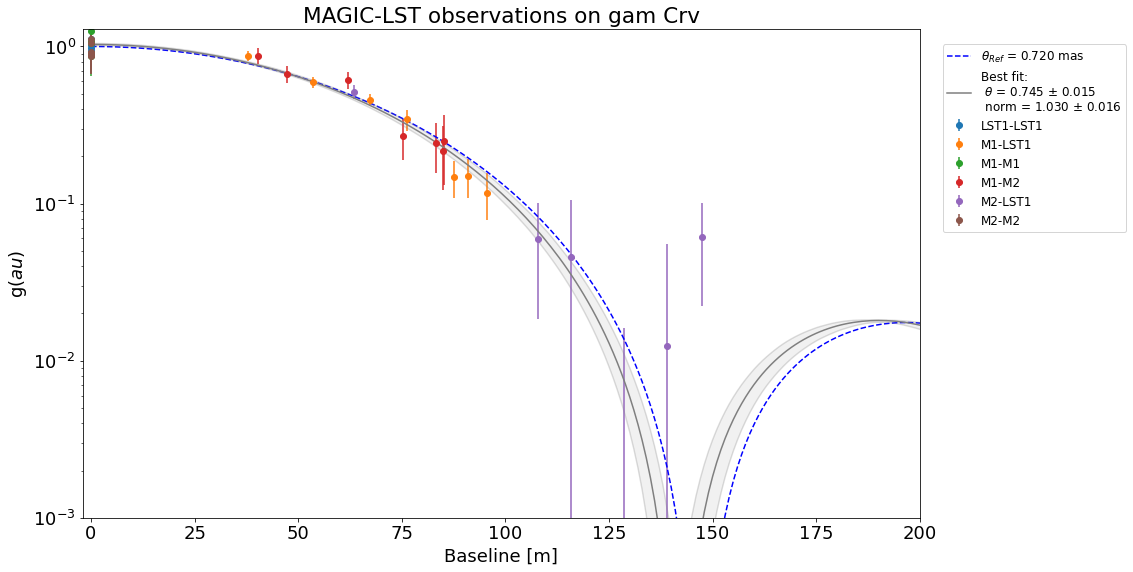

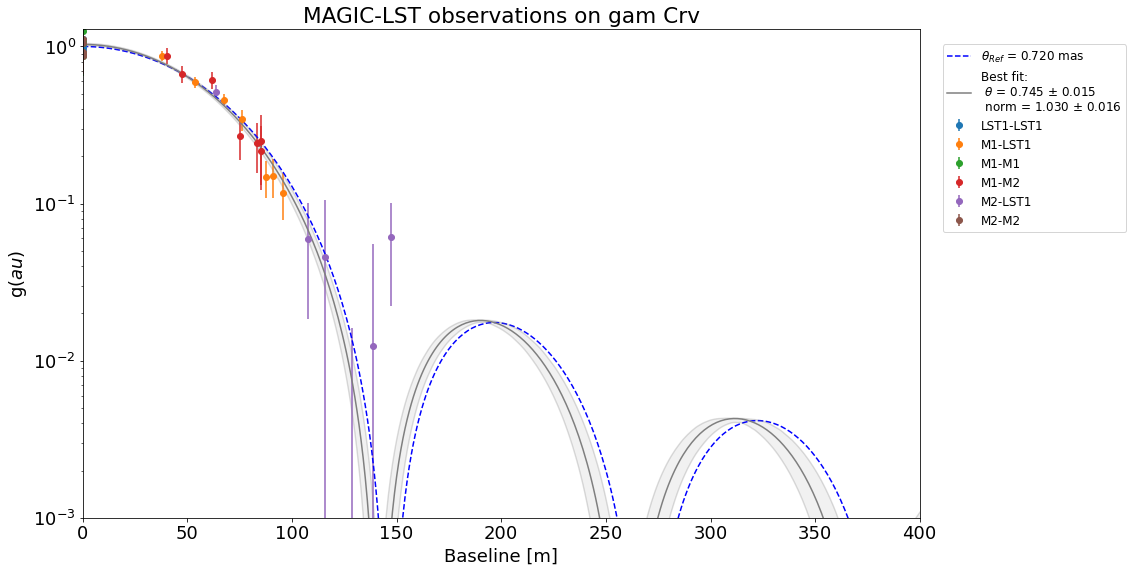

In [14]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("gam Crv", zbc_norm=1., observatory_name="MAGIC-LST")

times = ['2021-02-12T00:00:00',
         '2021-02-12T00:45:00',
         '2021-02-12T01:30:00',
         '2021-02-12T03:00:00', 
         '2021-02-12T04:30:00', 
         '2021-02-12T06:00:00', 
         '2021-02-12T07:30:00']
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.simulate_zbc_observations(time_array, run_duration=10*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
sim_run.f.get_axes()[0].set_xlim([0, 400])
sim_run.f

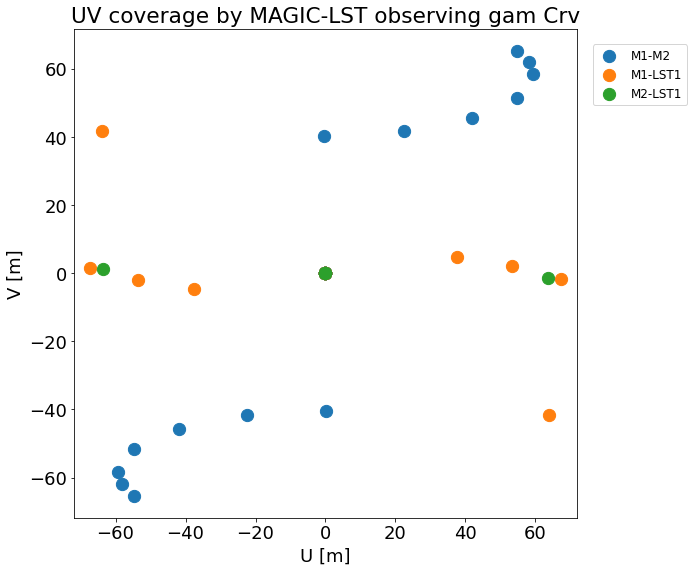

In [15]:
sim_run.plot_uv()

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (183.95154504, -17.54193046)>
Closest star found within the JMDC is:
 -Star ids: HD106625 or GAM CRV
- Stellar diameter: 0.72


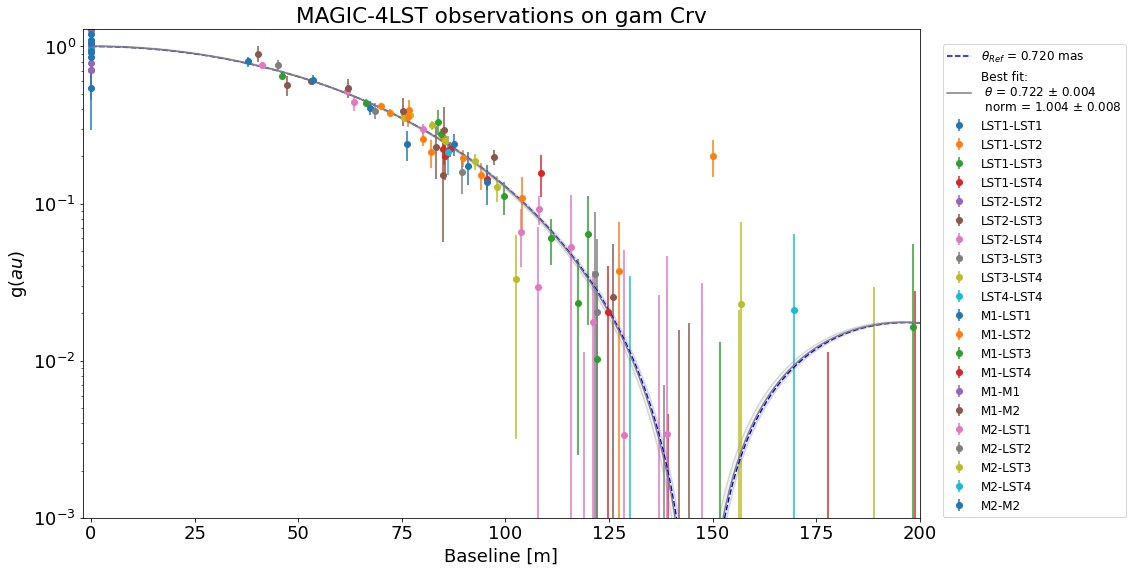

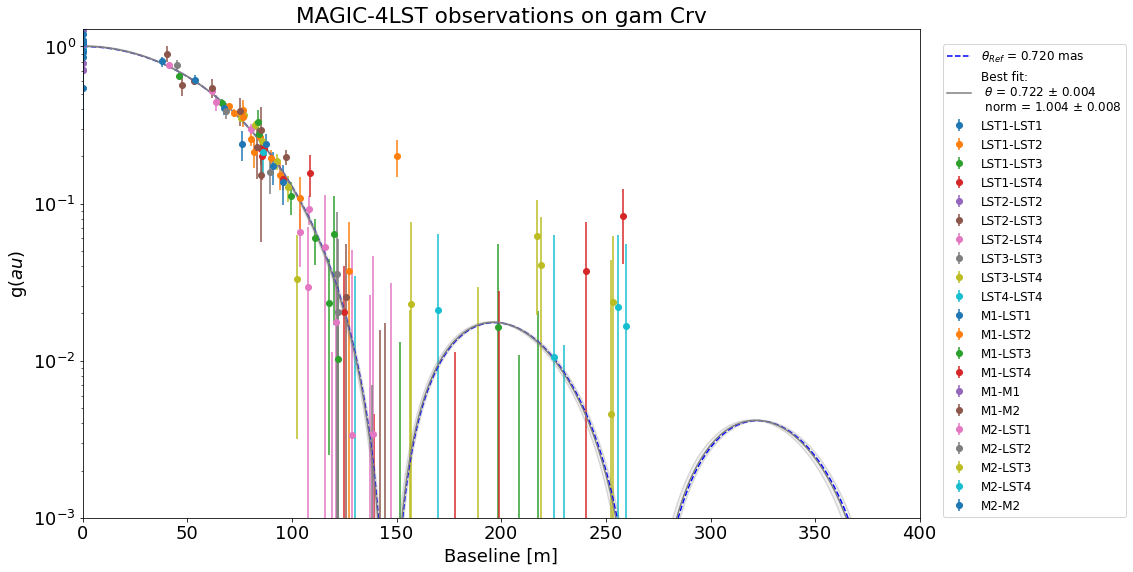

In [16]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("gam Crv", zbc_norm=1., observatory_name="MAGIC-4LST")

times = ['2021-02-12T00:00:00',
         '2021-02-12T00:45:00',
         '2021-02-12T01:30:00',
         '2021-02-12T03:00:00', 
         '2021-02-12T04:30:00', 
         '2021-02-12T06:00:00', 
         '2021-02-12T07:30:00']
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.simulate_zbc_observations(time_array, run_duration=10*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
sim_run.f.get_axes()[0].set_xlim([0, 400])
# sim_run.f.legend().set_bbox_to_anchor = (1.3, 1.00)
# sim_run.f.legend().set_loc='bottom left'
sim_run.f

In [22]:
# Let's assume the moon NSB is equivalent to a 6th mag star (not sure at all about this number...)
moon_magnitude_equivalent = 6.

n_simulations = 2
times = ['2021-02-12T00:00:00',
         '2021-02-12T00:45:00',
         '2021-02-12T01:30:00',
         '2021-02-12T03:00:00', 
         '2021-02-12T04:30:00', 
         '2021-02-12T06:00:00', 
         '2021-02-12T07:30:00']
time_array = Time(times, format='isot', scale='utc')

sim_run = SimulateSiiRuns("gam Crv", zbc_norm=1., observatory_name="MAGIC-LST")

individual_observing_times = [20.]
# individual_observing_times = [5., 10., 20.]
all_resulting_rel_error = []
all_resulting_rel_error_unc = []
for obs_time in individual_observing_times:

    magnitudes = np.arange(0, 5.5, 0.75)
    resulting_rel_error = []
    resulting_rel_error_unc = []


    for mag in magnitudes:
        print("Computing relative error of gam Crv if it was a mag {} star".format(mag))
        fit_norms = []
        fit_theta = []
        fit_relative_err = []
        # Here we artifitially modify the magnitude of the star
        sim_run.target_b_mag = mag 

        for i in np.arange(0, n_simulations, 1):
    #         if i%100 == 0:
    #             print("{}/{}".format(i, n_simulations))
            sim_run.simulate_observations(time_array, run_duration=obs_time*u.min, 
                                          moon_to_star_ratio=2.512**(sim_run.target_b_mag - moon_magnitude_equivalent))
            sim_run.simulate_zbc_observations(time_array, run_duration=obs_time*u.min, 
                                              moon_to_star_ratio=2.*(2.512**(sim_run.target_b_mag - moon_magnitude_equivalent)))
            sim_run.fit_uniform_disc()
            fit_results = sim_run.uniform_disc_fit
            fit_theta.append(fit_results['theta'])
            fit_norms.append(fit_results['norm'])
            fit_relative_err.append(fit_results['theta_e']/fit_results['theta'])
            sim_run.reset()
        resulting_rel_error.append(np.average(fit_relative_err))
        resulting_rel_error_unc.append(np.std(fit_relative_err))
    all_resulting_rel_error.append(resulting_rel_error)
    all_resulting_rel_error_unc.append(resulting_rel_error_unc)

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (183.95154504, -17.54193046)>
Closest star found within the JMDC is:
 -Star ids: HD106625 or GAM CRV
- Stellar diameter: 0.72
Computing relative error of gam Crv if it was a mag 0.0 star
Computing relative error of gam Crv if it was a mag 0.75 star
Computing relative error of gam Crv if it was a mag 1.5 star
Computing relative error of gam Crv if it was a mag 2.25 star
Computing relative error of gam Crv if it was a mag 3.0 star
Computing relative error of gam Crv if it was a mag 3.75 star
Computing relative error of gam Crv if it was a mag 4.5 star
Computing relative error of gam Crv if it was a mag 5.25 star


Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (249.28974606, -10.56709152)>
Closest star found within the JMDC is:
 -Star ids: HD149757 or ZET OPH
- Stellar diameter: 0.5


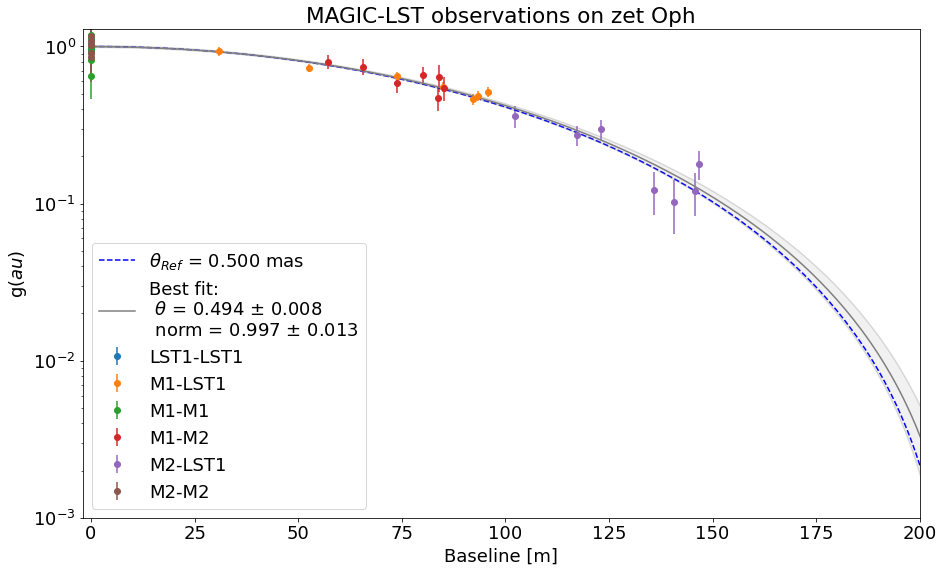

<Figure size 432x288 with 0 Axes>

In [15]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time


times = ['2021-05-14T22:00:00',
         '2021-05-14T23:00:00',
         '2021-05-15T00:10:00',
         '2021-05-15T01:00:00', 
         '2021-05-15T02:00:00', 
         '2021-05-15T03:00:00', 
         '2021-05-15T04:00:00']
time_array = Time(times, format='isot', scale='utc')

sim_run = SimulateSiiRuns("zet Oph", zbc_norm=1., observatory_name="MAGIC-LST")

#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.simulate_zbc_observations(time_array, run_duration=10*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
plt.tight_layout()
sim_run.f.savefig("MAGIC-LST1_zetOph_simulation.eps")

In [6]:
# Let's assume the moon NSB is equivalent to a 6th mag star (not sure at all about this number...)
moon_magnitude_equivalent = 6.

n_simulations = 10

times = ['2021-05-14T22:00:00',
         '2021-05-14T23:00:00',
         '2021-05-15T00:10:00',
         '2021-05-15T01:00:00', 
         '2021-05-15T02:00:00', 
         '2021-05-15T03:00:00', 
         '2021-05-15T04:00:00']
time_array = Time(times, format='isot', scale='utc')



results = dict()

# individual_observing_times = [5., 10., 20.]
individual_observing_times = [20.]
magnitudes = np.arange(0, 6.5, 0.75)
telescopes = ["MAGIC", "MAGIC-LST", "MAGIC-4LST", "MAGIC-CTA-N"]
for tel in telescopes:
    print("Simulating observations with the following array: {}".format(tel))
    sim_run = SimulateSiiRuns("zet Oph", zbc_norm=1., observatory_name=tel)
    results[tel] = dict()
    results[tel]['rel_error'] = []
    results[tel]['rel_error_unc'] = []
    for obs_time in individual_observing_times:

        resulting_rel_error = []
        resulting_rel_error_unc = []
        for mag in magnitudes:
            print("Computing relative error of gam Crv if it was a mag {} star".format(mag))
            fit_norms = []
            fit_theta = []
            fit_relative_err = []
            # Here we artifitially modify the magnitude of the star
            sim_run.target_b_mag = mag 

            for i in np.arange(0, n_simulations, 1):
        #         if i%100 == 0:
        #             print("{}/{}".format(i, n_simulations))
                sim_run.simulate_observations(time_array, run_duration=obs_time*u.min, 
                                              moon_to_star_ratio=2.512**(sim_run.target_b_mag - moon_magnitude_equivalent))
                sim_run.simulate_zbc_observations(time_array, run_duration=obs_time*u.min, 
                                                  moon_to_star_ratio=2.512**(sim_run.target_b_mag - moon_magnitude_equivalent))
                sim_run.fit_uniform_disc()
                fit_results = sim_run.uniform_disc_fit
                fit_theta.append(fit_results['theta'])
                fit_norms.append(fit_results['norm'])
                fit_relative_err.append(fit_results['theta_e']/fit_results['theta'])
                sim_run.reset()
            resulting_rel_error.append(np.average(fit_relative_err))
            resulting_rel_error_unc.append(np.std(fit_relative_err))
        results[tel]['rel_error'].append(resulting_rel_error)
        results[tel]['rel_error_unc'].append(resulting_rel_error_unc)

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (249.28974606, -10.56709152)>
Closest star found within the JMDC is:
 -Star ids: HD149757 or ZET OPH
- Stellar diameter: 0.5
Computing relative error of gam Crv if it was a mag 0.0 star
Computing relative error of gam Crv if it was a mag 0.75 star
Computing relative error of gam Crv if it was a mag 1.5 star
Computing relative error of gam Crv if it was a mag 2.25 star
Computing relative error of gam Crv if it was a mag 3.0 star
Computing relative error of gam Crv if it was a mag 3.75 star
Computing relative error of gam Crv if it was a mag 4.5 star
Computing relative error of gam Crv if it was a mag 5.25 star
Computing relative error of gam Crv if it was a mag 6.0 star
Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (249.28974606, -10.56709152)>
Closest star found within the JMDC is:
 -Star ids: HD149757 or ZET OPH
- Stellar diameter: 0.5
Computing relative error of gam Crv if it was

ERROR:root:The input observatory name (MAGIC-CTA-N) is not within the list of valid names.


ValueError: 

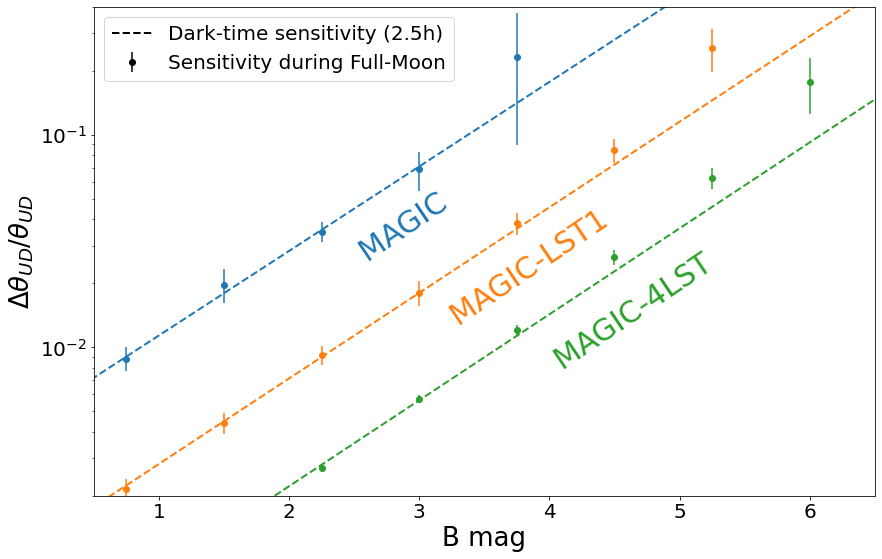

In [32]:
from scipy.optimize import curve_fit

# Function to calculate the power-law with constants a and b
def straight_line(x, a, b):
    return a*x + b

font = {'family' : 'normal',
#         'weight' : 'bold',
        'size'   : 20}

matplotlib.rc('font', **font)

f = plt.figure(figsize=(14, 9))
ax1 = f.add_subplot(111)

i=0
ax1.errorbar(magnitudes[0:6], results["MAGIC"]['rel_error'][i][0:6], 
             yerr=results["MAGIC"]['rel_error_unc'][i][0:6], fmt='o',
#              label="MAGIC: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)),
            )
ax1.errorbar(magnitudes[0:8], results["MAGIC-LST"]['rel_error'][i][0:8], 
             yerr=results["MAGIC-LST"]['rel_error_unc'][i][0:8], fmt='o',
#              label="MAGIC-LST1: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)),
            )
ax1.errorbar(magnitudes, results["MAGIC-4LST"]['rel_error'][i], 
             yerr=results["MAGIC-4LST"]['rel_error_unc'][i], fmt='o',
#              label="MAGIC-4LST: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)),
            )

ax1.errorbar(magnitudes, np.array(results["MAGIC-4LST"]['rel_error'][i])*1e-6, 
             yerr=np.array(results["MAGIC-4LST"]['rel_error_unc'][i])*1e-6, fmt='o', color='black',
             label="Sensitivity during Full-Moon")


pars_magic, cov_magic = curve_fit(f=straight_line, xdata=magnitudes[0:5], ydata=np.log10(results["MAGIC"]['rel_error'][i][0:5]), p0=[1, 4.])
pars_lst, cov_lst = curve_fit(f=straight_line, xdata=magnitudes[0:5], ydata=np.log10(results["MAGIC-LST"]['rel_error'][i][0:5]), p0=[1, 4.])
pars_4lst, cov_4lst = curve_fit(f=straight_line, xdata=magnitudes[0:5], ydata=np.log10(results["MAGIC-4LST"]['rel_error'][i][0:5]), p0=[1, 4.])

ext_magnitudes = np.arange(0, 6.5+0.75, 0.75)
# Plot the fit data as an overlay on the scatter data
ax1.plot(ext_magnitudes, 10**straight_line(ext_magnitudes, *pars_magic), linestyle="--", linewidth=2, color="C0")
ax1.plot(ext_magnitudes, 10**straight_line(ext_magnitudes, *pars_lst), linestyle="--", linewidth=2, color="C1")
ax1.plot(ext_magnitudes, 10**straight_line(ext_magnitudes, *pars_4lst), linestyle="--", linewidth=2, color="C2")
ax1.plot(ext_magnitudes, np.zeros_like(ext_magnitudes), linestyle="--", linewidth=2, color="black", 
         label="Dark-time sensitivity (2.5h)")
    
ax1.xaxis.set_label_text('B mag', fontsize=26)
ax1.yaxis.set_label_text(r'$\Delta\theta_{UD} / \theta_{UD}$', fontsize=26)

ax1.text(2.5, 2.6e-2, 'MAGIC', color='C0', rotation="34", fontsize=30)
ax1.text(3.2, 1.3e-2, 'MAGIC-LST1', color='C1', rotation="34", fontsize=30)
ax1.text(4.0, 8e-3, 'MAGIC-4LST', color='C2', rotation="34", fontsize=30)

ax1.set_yscale('log')
ax1.set_xlim([0.5, 6.5])
ax1.set_ylim([2e-3, 0.4])
ax1.legend()
f.savefig("gam_crv_simulation.pdf", bbox_inches='tight')

In [35]:
print(ext_magnitudes, pars_magic)

[0.   0.75 1.5  2.25 3.   3.75 4.5  5.25 6.   6.75] [ 0.39755697 -2.34275854]


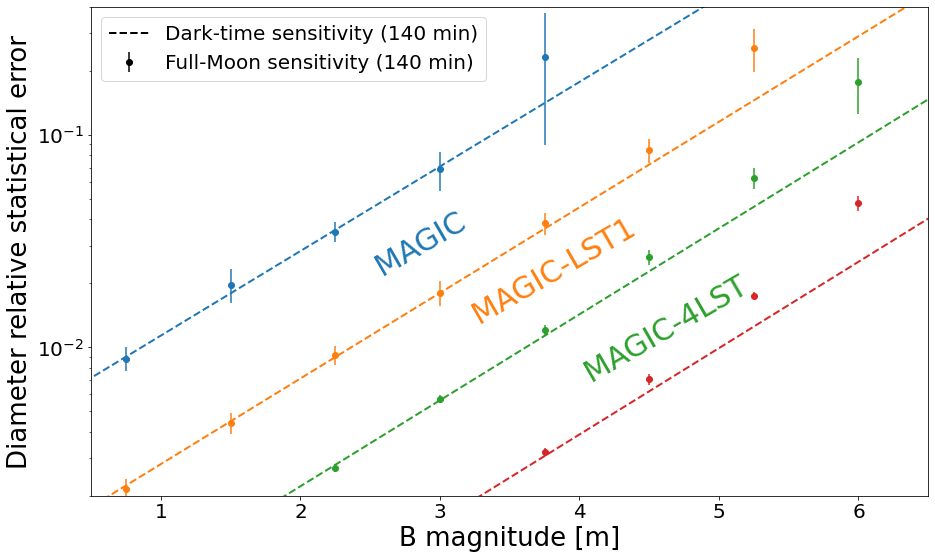

In [24]:
from scipy.optimize import curve_fit

# Function to calculate the power-law with constants a and b
def straight_line(x, a, b):
    return a*x + b

font = {'family' : 'normal',
#         'weight' : 'bold',
        'size'   : 20}

matplotlib.rc('font', **font)

f = plt.figure(figsize=(15, 9))
ax1 = f.add_subplot(111)

i=0
ax1.errorbar(magnitudes[0:6], results["MAGIC"]['rel_error'][i][0:6], 
             yerr=results["MAGIC"]['rel_error_unc'][i][0:6], fmt='o',
#              label="MAGIC: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)),
            )
ax1.errorbar(magnitudes[0:8], results["MAGIC-LST"]['rel_error'][i][0:8], 
             yerr=results["MAGIC-LST"]['rel_error_unc'][i][0:8], fmt='o',
#              label="MAGIC-LST1: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)),
            )
ax1.errorbar(magnitudes, results["MAGIC-4LST"]['rel_error'][i], 
             yerr=results["MAGIC-4LST"]['rel_error_unc'][i], fmt='o',
#              label="MAGIC-4LST: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)),
            )

ax1.errorbar(magnitudes, results["MAGIC-4LST-microstars"]['rel_error'][i], 
             yerr=results["MAGIC-4LST-microstars"]['rel_error_unc'][i], fmt='o',
#              label="MAGIC-4LST: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)),
            )


ax1.errorbar(magnitudes, np.array(results["MAGIC-4LST"]['rel_error'][i])*1e-6, 
             yerr=np.array(results["MAGIC-4LST"]['rel_error_unc'][i])*1e-6, fmt='o', color='black',
             label="Full-Moon sensitivity ({:2.0f} min)".format(individual_observing_times[i]*len(time_array)))


pars_magic, cov_magic = curve_fit(f=straight_line, xdata=magnitudes[0:5], ydata=np.log10(results["MAGIC"]['rel_error'][i][0:5]), p0=[1, 4.])
pars_lst, cov_lst = curve_fit(f=straight_line, xdata=magnitudes[0:5], ydata=np.log10(results["MAGIC-LST"]['rel_error'][i][0:5]), p0=[1, 4.])
pars_4lst, cov_4lst = curve_fit(f=straight_line, xdata=magnitudes[0:5], ydata=np.log10(results["MAGIC-4LST"]['rel_error'][i][0:5]), p0=[1, 4.])
pars_4lst_ms, cov_4lst_ms = curve_fit(f=straight_line, xdata=magnitudes[0:5], 
                                      ydata=np.log10(results["MAGIC-4LST-microstars"]['rel_error'][i][0:5]), p0=[1, 4.])

ext_magnitudes = np.arange(0, 6.5+0.75, 0.75)
# Plot the fit data as an overlay on the scatter data
ax1.plot(ext_magnitudes, 10**straight_line(ext_magnitudes, *pars_magic), linestyle="--", linewidth=2, color="C0")
ax1.plot(ext_magnitudes, 10**straight_line(ext_magnitudes, *pars_lst), linestyle="--", linewidth=2, color="C1")
ax1.plot(ext_magnitudes, 10**straight_line(ext_magnitudes, *pars_4lst), linestyle="--", linewidth=2, color="C2")
ax1.plot(ext_magnitudes, 10**straight_line(ext_magnitudes, *pars_4lst_ms), linestyle="--", linewidth=2, color="C3")
ax1.plot(ext_magnitudes, np.zeros_like(ext_magnitudes), linestyle="--", linewidth=2, color="black", 
         label="Dark-time sensitivity ({:2.0f} min)".format(individual_observing_times[i]*len(time_array)))
    
ax1.xaxis.set_label_text('B magnitude [m]', fontsize=26)
ax1.yaxis.set_label_text('Diameter relative statistical error', fontsize=26)

ax1.text(2.5, 2.2e-2, 'MAGIC', color='C0', rotation="30", fontsize=30)
ax1.text(3.2, 1.3e-2, 'MAGIC-LST1', color='C1', rotation="30", fontsize=30)
ax1.text(4.0, 7e-3, 'MAGIC-4LST', color='C2', rotation="30", fontsize=30)

ax1.set_yscale('log')
ax1.set_xlim([0.5, 6.5])
ax1.set_ylim([2e-3, 0.4])
ax1.legend()
f.savefig("gam_crv_simulation.pdf", bbox_inches='tight')

In [ ]:
from scipy.optimize import curve_fit

# Function to calculate the power-law with constants a and b
def straight_line(x, a, b):
    return a*x + b

font = {'family' : 'normal',
#         'weight' : 'bold',
        'size'   : 20}

matplotlib.rc('font', **font)

f = plt.figure(figsize=(15, 9))
ax1 = f.add_subplot(111)

i=0
ax1.errorbar(magnitudes[0:6], results["MAGIC"]['rel_error'][i][0:6], 
             yerr=results["MAGIC"]['rel_error_unc'][i][0:6], fmt='o',
             label="MAGIC: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)))
ax1.errorbar(magnitudes[0:8], results["MAGIC-LST"]['rel_error'][i][0:8], 
             yerr=results["MAGIC-LST"]['rel_error_unc'][i][0:8], fmt='o',
             label="MAGIC-LST1: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)))
ax1.errorbar(magnitudes, results["MAGIC-4LST"]['rel_error'][i], 
             yerr=results["MAGIC-4LST"]['rel_error_unc'][i], fmt='o',
             label="MAGIC-4LST: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)))

pars_magic, cov_magic = curve_fit(f=straight_line, xdata=magnitudes[0:5], ydata=np.log10(results["MAGIC"]['rel_error'][i][0:5]), p0=[1, 4.])
pars_lst, cov_lst = curve_fit(f=straight_line, xdata=magnitudes[0:5], ydata=np.log10(results["MAGIC-LST"]['rel_error'][i][0:5]), p0=[1, 4.])
pars_4lst, cov_4lst = curve_fit(f=straight_line, xdata=magnitudes[0:5], ydata=np.log10(results["MAGIC-4LST"]['rel_error'][i][0:5]), p0=[1, 4.])

ext_magnitudes = np.arange(0, 6.5+0.75, 0.75)
# Plot the fit data as an overlay on the scatter data
ax1.plot(ext_magnitudes, 10**straight_line(ext_magnitudes, *pars_magic), linestyle="--", linewidth=2, color="C0")
ax1.plot(ext_magnitudes, 10**straight_line(ext_magnitudes, *pars_lst), linestyle="--", linewidth=2, color="C1")
ax1.plot(ext_magnitudes, 10**straight_line(ext_magnitudes, *pars_4lst), linestyle="--", linewidth=2, color="C2")
ax1.plot(ext_magnitudes, np.zeros_like(ext_magnitudes), linestyle="--", linewidth=2, color="black", 
         label="Dark-time sensitivity")
    
ax1.xaxis.set_label_text('B magnitude [m]', fontsize=26)
ax1.yaxis.set_label_text('Diameter relative statistical error', fontsize=26)

ax1.set_yscale('log')
ax1.set_xlim([0.5, 6.5])
ax1.set_ylim([1e-3, 0.4])
ax1.legend()
    

In [24]:
sim_run = SimulateSiiRuns("zet Oph", zbc_norm=1., observatory_name="MAGIC-LST")

# individual_observing_times = [5., 10., 20.]
lst1_all_resulting_rel_error = []
lst1_all_resulting_rel_error_unc = []
for obs_time in individual_observing_times:

    magnitudes = np.arange(0, 5.5, 0.75)
    resulting_rel_error = []
    resulting_rel_error_unc = []


    for mag in magnitudes:
        print("Computing relative error of gam Crv if it was a mag {} star".format(mag))
        fit_norms = []
        fit_theta = []
        fit_relative_err = []
        # Here we artifitially modify the magnitude of the star
        sim_run.target_b_mag = mag 

        for i in np.arange(0, n_simulations, 1):
    #         if i%100 == 0:
    #             print("{}/{}".format(i, n_simulations))
            sim_run.simulate_observations(time_array, run_duration=obs_time*u.min, 
                                          moon_to_star_ratio=2.512**(sim_run.target_b_mag - moon_magnitude_equivalent))
            sim_run.simulate_zbc_observations(time_array, run_duration=obs_time*u.min, 
                                              moon_to_star_ratio=2.512**(sim_run.target_b_mag - moon_magnitude_equivalent))
            sim_run.fit_uniform_disc()
            fit_results = sim_run.uniform_disc_fit
            fit_theta.append(fit_results['theta'])
            fit_norms.append(fit_results['norm'])
            fit_relative_err.append(fit_results['theta_e']/fit_results['theta'])
            sim_run.reset()
        resulting_rel_error.append(np.average(fit_relative_err))
        resulting_rel_error_unc.append(np.std(fit_relative_err))
    lst1_all_resulting_rel_error.append(resulting_rel_error)
    lst1_all_resulting_rel_error_unc.append(resulting_rel_error_unc)

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (249.28974606, -10.56709152)>
Closest star found within the JMDC is:
 -Star ids: HD149757 or ZET OPH
- Stellar diameter: 0.5
Computing relative error of gam Crv if it was a mag 0.0 star
Computing relative error of gam Crv if it was a mag 0.75 star
Computing relative error of gam Crv if it was a mag 1.5 star
Computing relative error of gam Crv if it was a mag 2.25 star
Computing relative error of gam Crv if it was a mag 3.0 star
Computing relative error of gam Crv if it was a mag 3.75 star
Computing relative error of gam Crv if it was a mag 4.5 star
Computing relative error of gam Crv if it was a mag 5.25 star


In [14]:
sim_run = SimulateSiiRuns("zet Oph", zbc_norm=1., observatory_name="MAGIC-4LST")

individual_observing_times = [5., 10., 20.]
all_resulting_rel_error = []
all_resulting_rel_error_unc = []
for obs_time in individual_observing_times:

    magnitudes = np.arange(0, 5.5, 0.75)
    resulting_rel_error = []
    resulting_rel_error_unc = []


    for mag in magnitudes:
        print("Computing relative error of gam Crv if it was a mag {} star".format(mag))
        fit_norms = []
        fit_theta = []
        fit_relative_err = []
        # Here we artifitially modify the magnitude of the star
        sim_run.target_b_mag = mag 

        for i in np.arange(0, n_simulations, 1):
    #         if i%100 == 0:
    #             print("{}/{}".format(i, n_simulations))
            sim_run.simulate_observations(time_array, run_duration=obs_time*u.min, 
                                          moon_to_star_ratio=2.512**(sim_run.target_b_mag - moon_magnitude_equivalent))
            sim_run.simulate_zbc_observations(time_array, run_duration=obs_time*u.min, 
                                              moon_to_star_ratio=2.512**(sim_run.target_b_mag - moon_magnitude_equivalent))
            sim_run.fit_uniform_disc()
            fit_results = sim_run.uniform_disc_fit
            fit_theta.append(fit_results['theta'])
            fit_norms.append(fit_results['norm'])
            fit_relative_err.append(fit_results['theta_e']/fit_results['theta'])
            sim_run.reset()
        resulting_rel_error.append(np.average(fit_relative_err))
        resulting_rel_error_unc.append(np.std(fit_relative_err))
    all_resulting_rel_error.append(resulting_rel_error)
    all_resulting_rel_error_unc.append(resulting_rel_error_unc)

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (249.28974606, -10.56709152)>
Closest star found within the JMDC is:
 -Star ids: HD149757 or ZET OPH
- Stellar diameter: 0.5
Computing relative error of gam Crv if it was a mag 0.0 star
Computing relative error of gam Crv if it was a mag 0.75 star
Computing relative error of gam Crv if it was a mag 1.5 star
Computing relative error of gam Crv if it was a mag 2.25 star
Computing relative error of gam Crv if it was a mag 3.0 star
Computing relative error of gam Crv if it was a mag 3.75 star
Computing relative error of gam Crv if it was a mag 4.5 star
Computing relative error of gam Crv if it was a mag 5.25 star
Computing relative error of gam Crv if it was a mag 0.0 star
Computing relative error of gam Crv if it was a mag 0.75 star
Computing relative error of gam Crv if it was a mag 1.5 star
Computing relative error of gam Crv if it was a mag 2.25 star
Computing relative error of gam Crv if it was a mag 3.0 star


In [4]:
sim_run = SimulateSiiRuns("zet Oph", zbc_norm=1., observatory_name="MAGIC-4LST-microstars")

individual_observing_times = [5., 10., 20.]
ms_all_resulting_rel_error = []
ms_all_resulting_rel_error_unc = []
for obs_time in individual_observing_times:

    magnitudes = np.arange(0, 5.5, 0.75)
    resulting_rel_error = []
    resulting_rel_error_unc = []


    for mag in magnitudes:
        print("Computing relative error of gam Crv if it was a mag {} star".format(mag))
        fit_norms = []
        fit_theta = []
        fit_relative_err = []
        # Here we artifitially modify the magnitude of the star
        sim_run.target_b_mag = mag 

        for i in np.arange(0, n_simulations, 1):
    #         if i%100 == 0:
    #             print("{}/{}".format(i, n_simulations))
            sim_run.simulate_observations(time_array, run_duration=obs_time*u.min, 
                                          moon_to_star_ratio=2.512**(sim_run.target_b_mag - moon_magnitude_equivalent))
            sim_run.simulate_zbc_observations(time_array, run_duration=obs_time*u.min, 
                                              moon_to_star_ratio=2.512**(sim_run.target_b_mag - moon_magnitude_equivalent))
            sim_run.fit_uniform_disc()
            fit_results = sim_run.uniform_disc_fit
            fit_theta.append(fit_results['theta'])
            fit_norms.append(fit_results['norm'])
            fit_relative_err.append(fit_results['theta_e']/fit_results['theta'])
            sim_run.reset()
        resulting_rel_error.append(np.average(fit_relative_err))
        resulting_rel_error_unc.append(np.std(fit_relative_err))
    ms_all_resulting_rel_error.append(resulting_rel_error)
    ms_all_resulting_rel_error_unc.append(resulting_rel_error_unc)


Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (249.28974606, -10.56709152)>
Closest star found within the JMDC is:
 -Star ids: HD149757 or ZET OPH
- Stellar diameter: 0.5
Computing relative error of gam Crv if it was a mag 0.0 star
Computing relative error of gam Crv if it was a mag 0.75 star
Computing relative error of gam Crv if it was a mag 1.5 star
Computing relative error of gam Crv if it was a mag 2.25 star
Computing relative error of gam Crv if it was a mag 3.0 star
Computing relative error of gam Crv if it was a mag 3.75 star
Computing relative error of gam Crv if it was a mag 4.5 star
Computing relative error of gam Crv if it was a mag 5.25 star
Computing relative error of gam Crv if it was a mag 0.0 star
Computing relative error of gam Crv if it was a mag 0.75 star
Computing relative error of gam Crv if it was a mag 1.5 star
Computing relative error of gam Crv if it was a mag 2.25 star
Computing relative error of gam Crv if it was a mag 3.0 star


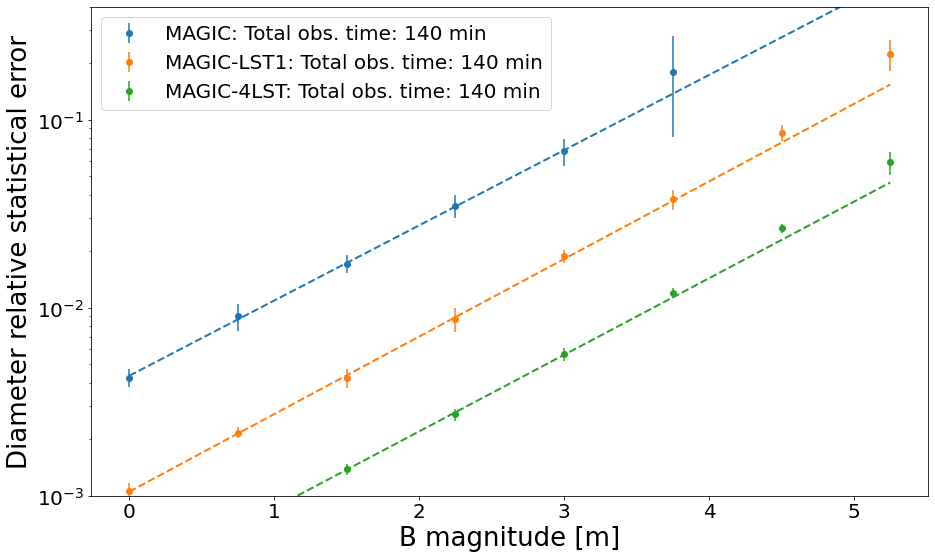

In [21]:
from scipy.optimize import curve_fit

# Function to calculate the power-law with constants a and b
def straight_line(x, a, b):
    return a*x + b

font = {'family' : 'normal',
#         'weight' : 'bold',
        'size'   : 20}

matplotlib.rc('font', **font)

f = plt.figure(figsize=(15, 9))
ax1 = f.add_subplot(111)


i=2
ax1.errorbar(magnitudes[0:6], magic_all_resulting_rel_error[i][0:6], yerr=magic_all_resulting_rel_error_unc[i][0:6], fmt='o',
             label="MAGIC: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)))
ax1.errorbar(magnitudes, lst1_all_resulting_rel_error[i], yerr=lst1_all_resulting_rel_error_unc[i], fmt='o',
             label="MAGIC-LST1: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)))
ax1.errorbar(magnitudes, all_resulting_rel_error[i], yerr=all_resulting_rel_error_unc[i], fmt='o',
             label="MAGIC-4LST: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)))

pars_4lst, cov_4lst = curve_fit(f=straight_line, xdata=magnitudes[0:5], ydata=np.log10(all_resulting_rel_error[i][0:5]), p0=[1, 4.])
pars_lst, cov_lst = curve_fit(f=straight_line, xdata=magnitudes[0:5], ydata=np.log10(lst1_all_resulting_rel_error[i][0:5]), p0=[1, 4.])
pars_magic, cov_magic = curve_fit(f=straight_line, xdata=magnitudes[0:5], ydata=np.log10(magic_all_resulting_rel_error[i][0:5]), p0=[1, 4.])

# Plot the fit data as an overlay on the scatter data
ax1.plot(magnitudes, 10**straight_line(magnitudes, *pars_magic), linestyle="--", linewidth=2, color="C0")
ax1.plot(magnitudes, 10**straight_line(magnitudes, *pars_lst), linestyle="--", linewidth=2, color="C1")
ax1.plot(magnitudes, 10**straight_line(magnitudes, *pars_4lst), linestyle="--", linewidth=2, color="C2")
    
ax1.xaxis.set_label_text('B magnitude [m]', fontsize=26)
ax1.yaxis.set_label_text('Diameter relative statistical error', fontsize=26)

ax1.set_yscale('log')
ax1.set_ylim([1e-3, 0.4])
ax1.legend()
    

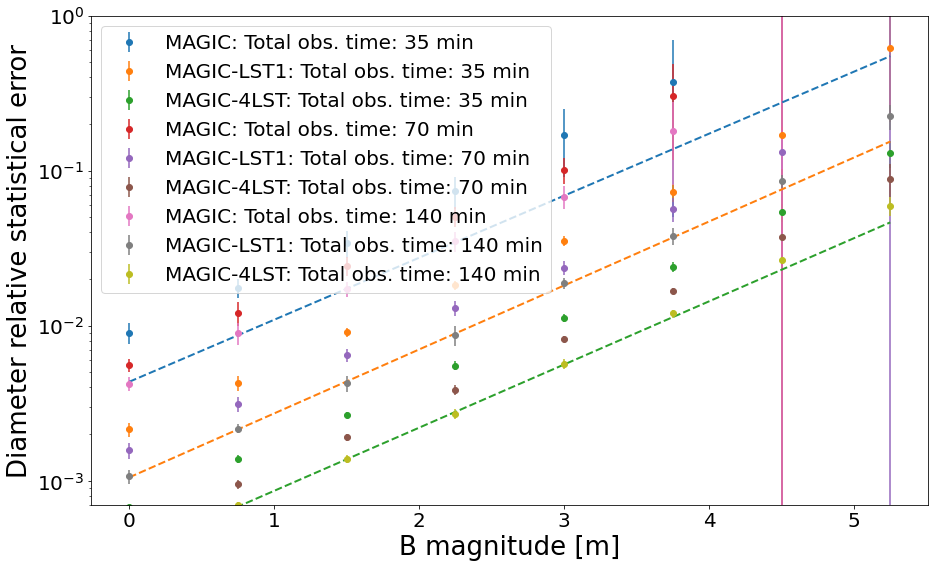

In [15]:
from scipy.optimize import curve_fit

# Function to calculate the power-law with constants a and b
def straight_line(x, a, b):
    return a*x + b

font = {'family' : 'normal',
#         'weight' : 'bold',
        'size'   : 20}

matplotlib.rc('font', **font)

f = plt.figure(figsize=(15, 9))
ax1 = f.add_subplot(111)


for i, obs_time in enumerate(individual_observing_times):
    ax1.errorbar(magnitudes[0:7], magic_all_resulting_rel_error[i][0:7], yerr=magic_all_resulting_rel_error_unc[i][0:7], fmt='o',
                 label="MAGIC: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)))
    ax1.errorbar(magnitudes, lst1_all_resulting_rel_error[i], yerr=lst1_all_resulting_rel_error_unc[i], fmt='o',
                 label="MAGIC-LST1: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)))
    ax1.errorbar(magnitudes, all_resulting_rel_error[i], yerr=all_resulting_rel_error_unc[i], fmt='o',
                 label="MAGIC-4LST: Total obs. time: {:2.0f} min".format(individual_observing_times[i]*len(time_array)))

    pars_4lst, cov_4lst = curve_fit(f=straight_line, xdata=magnitudes[0:5], ydata=np.log10(all_resulting_rel_error[i][0:5]), p0=[1, 4.])
    pars_lst, cov_lst = curve_fit(f=straight_line, xdata=magnitudes[0:5], ydata=np.log10(lst1_all_resulting_rel_error[i][0:5]), p0=[1, 4.])
    pars_magic, cov_magic = curve_fit(f=straight_line, xdata=magnitudes[0:5], ydata=np.log10(magic_all_resulting_rel_error[i][0:5]), p0=[1, 4.])

# Plot the fit data as an overlay on the scatter data
ax1.plot(magnitudes, 10**straight_line(magnitudes, *pars_magic), linestyle="--", linewidth=2, color="C0")
ax1.plot(magnitudes, 10**straight_line(magnitudes, *pars_lst), linestyle="--", linewidth=2, color="C1")
ax1.plot(magnitudes, 10**straight_line(magnitudes, *pars_4lst), linestyle="--", linewidth=2, color="C2")
    
ax1.xaxis.set_label_text('B magnitude [m]', fontsize=26)
ax1.yaxis.set_label_text('Diameter relative statistical error', fontsize=26)

ax1.set_yscale('log')
ax1.set_ylim([7e-4, 1.])
ax1.legend()
    

In [19]:
time_array

<Time object: scale='utc' format='isot' value=['2021-02-22T21:00:00.000' '2021-02-22T21:30:00.000'
 '2021-02-22T22:00:00.000' '2021-02-22T22:30:00.000'
 '2021-02-22T23:00:00.000' '2021-02-22T23:30:00.000']>

## Simulation gam Crv
---------

Closest star found within the JMDC is:
 -Star ids: HD37742 or * zet Ori A
- Stellar diameter: 0.47


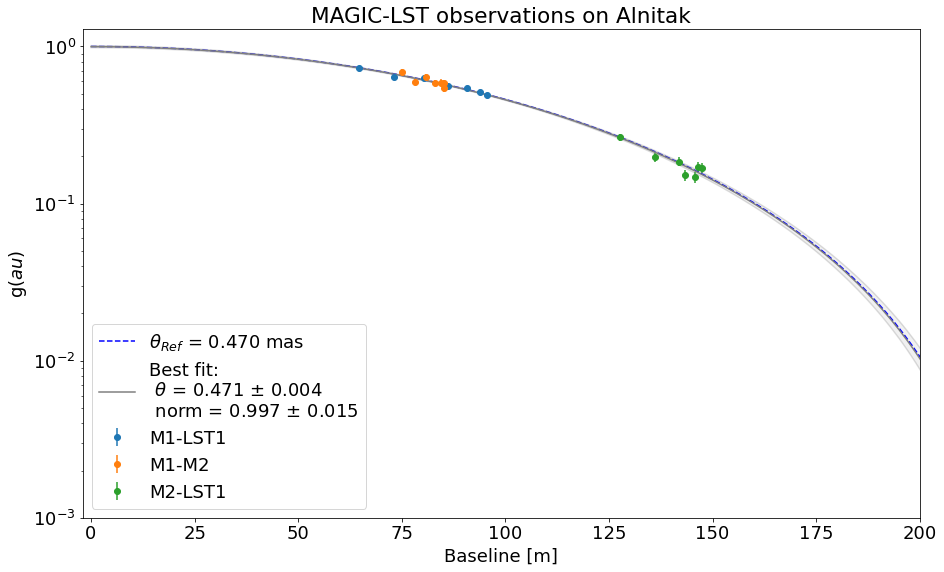

In [8]:
sim_run = SimulateSiiRuns("Alnitak", zbc_norm=1., observatory_name="MAGIC-LST")
times = ['2021-12-20T22:00:00', 
         '2021-12-20T22:30:00', 
         '2021-12-20T23:00:00', 
         '2021-12-20T23:30:00', 
         '2021-12-21T00:00:00', 
         '2021-12-21T00:30:00',
         '2021-12-21T01:00:00']
time_array = Time(times, format='isot', scale='utc')
sim_run.simulate_observations(time_array, run_duration=22*u.min)
sim_run.fit_uniform_disc()
sim_run.plot_v2()

Closest star found within the JMDC is:
 -Star ids: HD176437 or GAM LYR
- Stellar diameter: 0.729


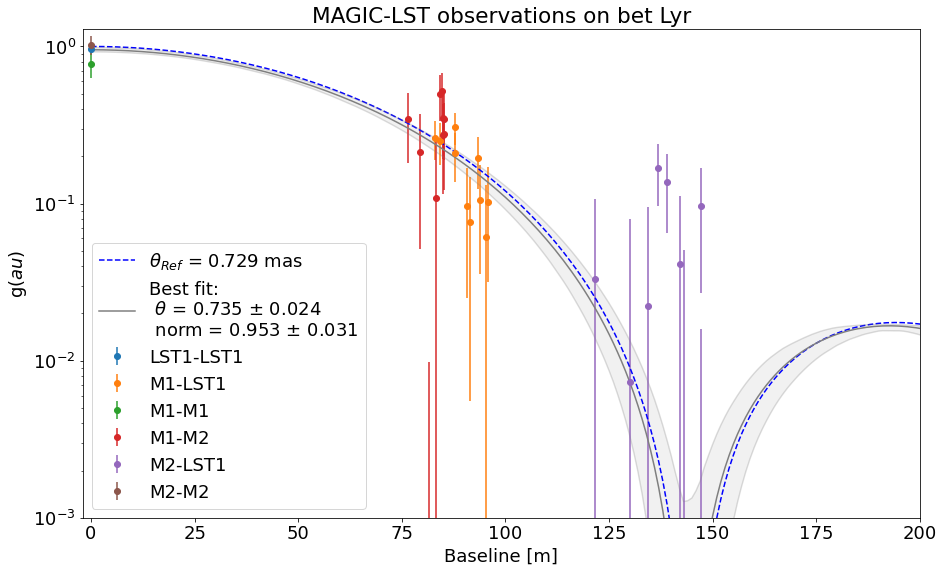

In [9]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("bet Lyr", zbc_norm=1., observatory_name="MAGIC-LST")

times = ['2021-06-10T00:00:00',
         '2021-06-10T00:30:00',
         '2021-06-10T01:00:00',
         '2021-06-10T01:30:00', 
         '2021-06-10T02:30:00', 
         '2021-06-10T03:00:00', 
         '2021-06-10T03:30:00', 
         '2021-06-10T04:00:00', 
         '2021-06-10T04:30:00', 
         '2021-06-10T05:00:00']
time_array = Time(times, format='isot', scale='utc')
zbc_times = ['2021-06-10T03:00:00']
zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=30*u.min)
sim_run.simulate_zbc_observations(zbc_time_array, run_duration=60*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)

Simulation Gam Cas
===========

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (152.09296244, 11.96720878)>
Closest star found within the JMDC is:
 -Star ids: HD87901 or ALF LEO
- Stellar diameter: 1.33


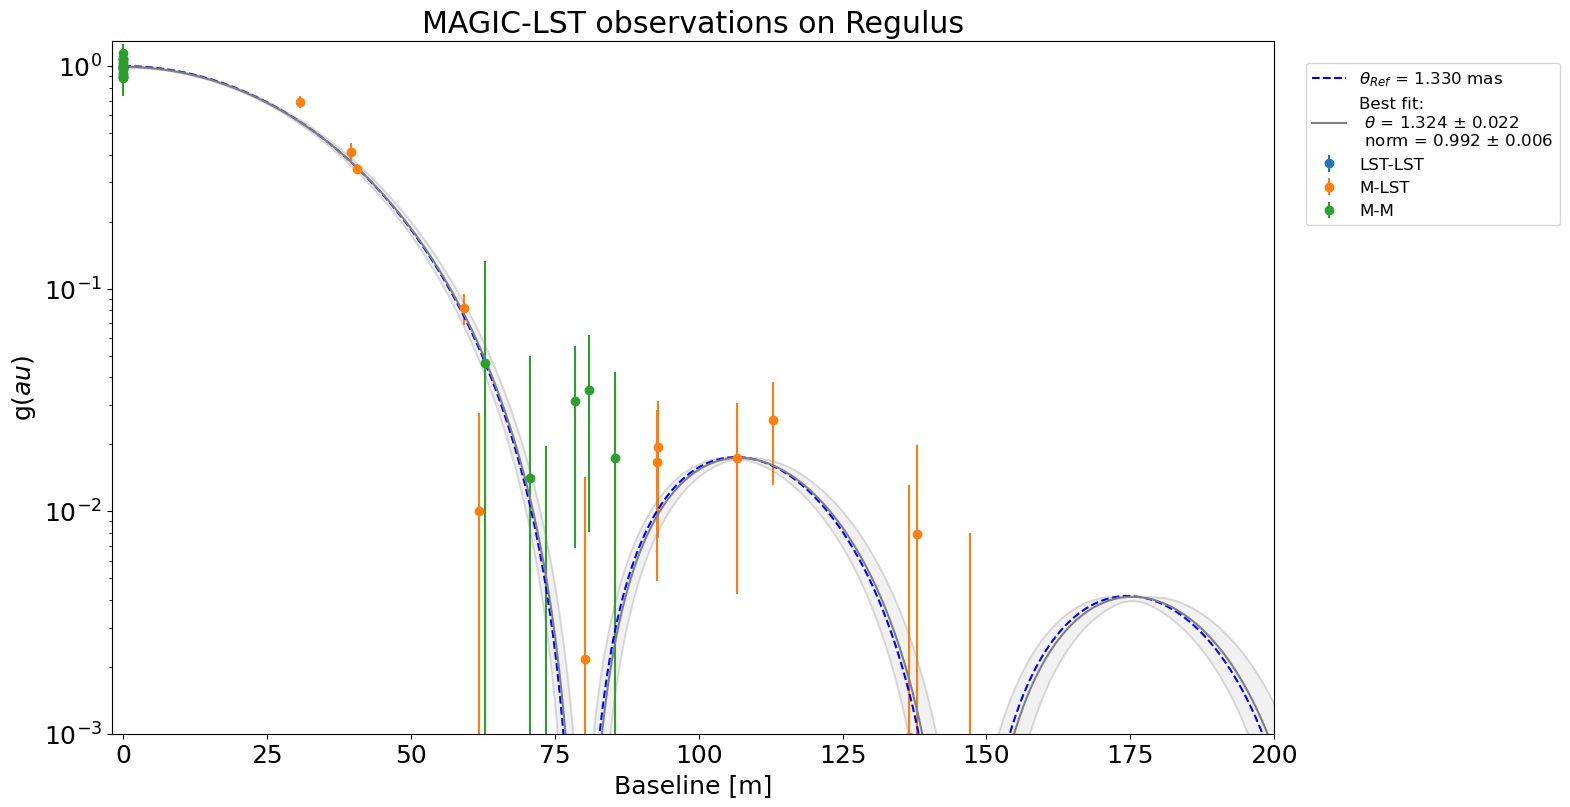

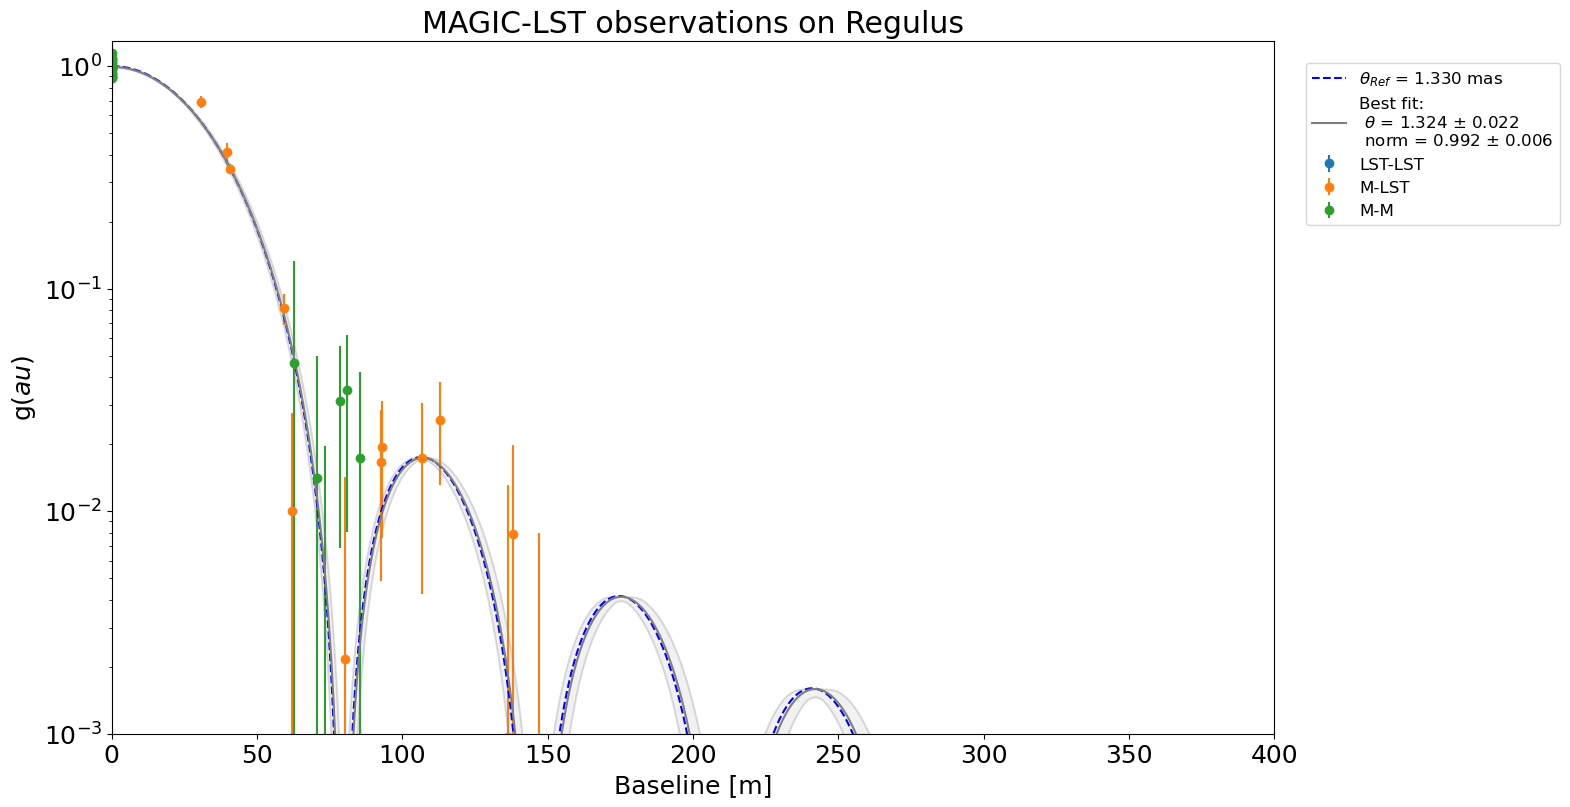

In [4]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("Regulus", zbc_norm=1., observatory_name="MAGIC-LST")

times = ['2021-03-12T19:00:00',
         '2021-03-12T20:30:00',
         '2021-03-12T22:00:00',
         '2021-03-12T23:30:00', 
         '2021-03-13T01:00:00', 
         '2021-03-13T02:30:00']
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.simulate_zbc_observations(time_array, run_duration=10*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
sim_run.f.get_axes()[0].set_xlim([0, 400])
# sim_run.f.legend().set_bbox_to_anchor = (1.3, 1.00)
# sim_run.f.legend().set_loc='bottom left'
sim_run.f

Simulation Adhara:
=========

In [20]:
sim_run = SimulateSiiRuns("Adhara", zbc_norm=1., observatory_name="MAGIC")

Closest star found within the JMDC is:
 -Star ids: HD52089 or EPS CMA


In [21]:
times = ['2021-02-22T21:00:00', 
         '2021-02-22T21:30:00', 
         '2021-02-22T22:00:00', 
         '2021-02-22T22:30:00', 
         '2021-02-22T23:00:00', 
         '2021-02-22T23:30:00']
time_array = Time(times, format='isot', scale='utc')

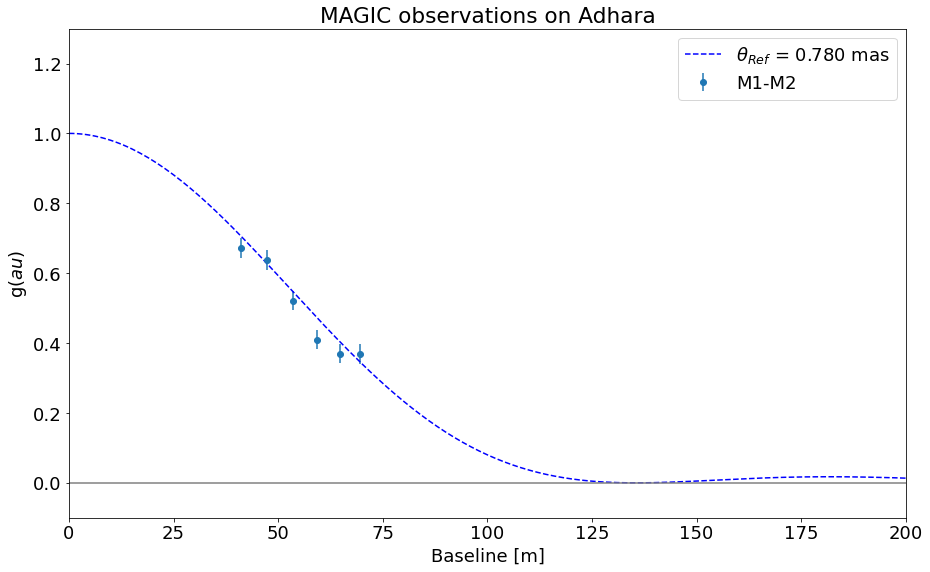

In [22]:
sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.plot_v2()

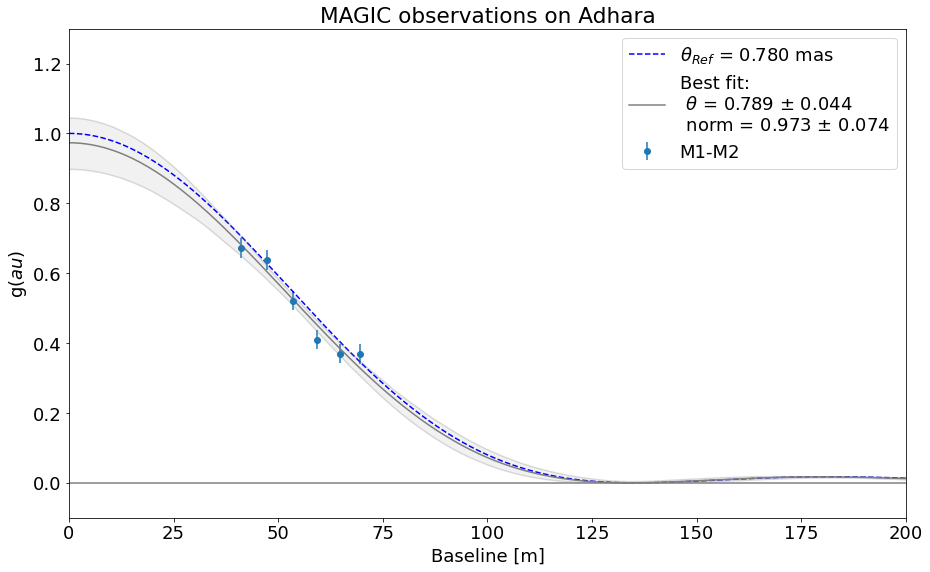

In [23]:
sim_run.fit_uniform_disc()
sim_run.plot_v2()

In [19]:
0.016/0.794


0.020151133501259445

In [24]:
0.044/0.794


0.05541561712846347

Closest star found within the JMDC is:
 -Star ids: HD120315 or eta UMa
- Stellar diameter: 0.937
1.6700001


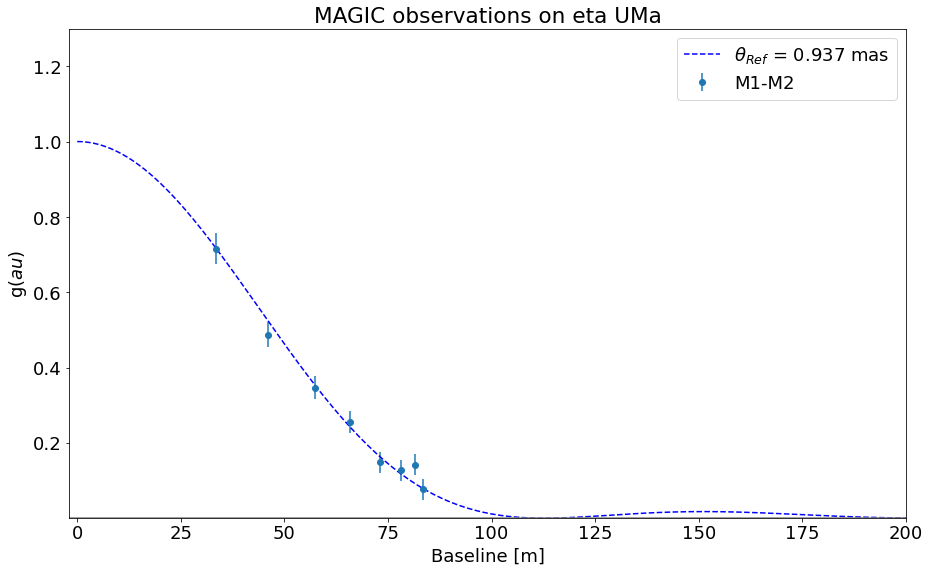

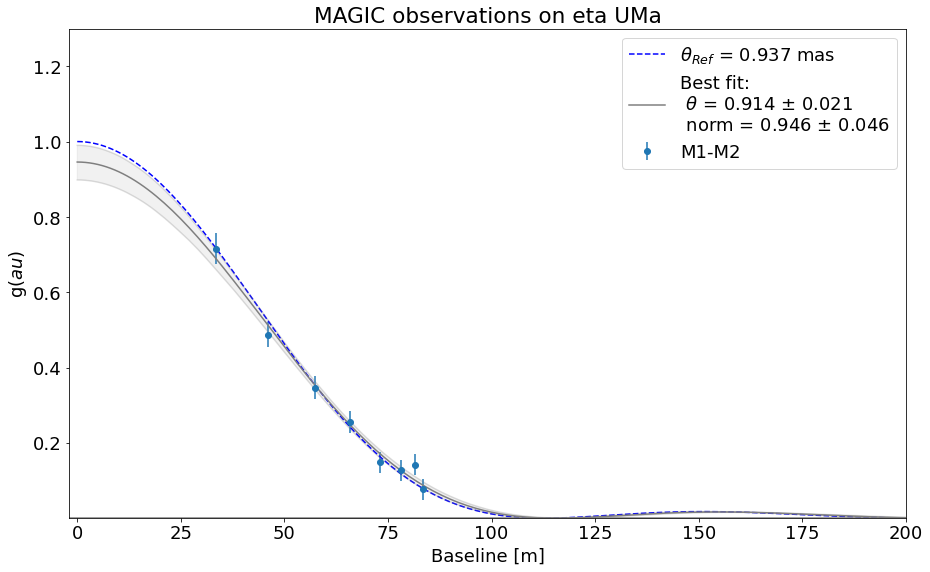

In [6]:
sim_run = SimulateSiiRuns("eta UMa", zbc_norm=1., observatory_name="MAGIC")
times = ['2021-03-10T21:30:00', 
         '2021-03-10T22:30:00', 
         '2021-03-10T23:30:00', 
         '2021-03-10T00:30:00', 
         '2021-03-10T01:30:00', 
         '2021-03-10T02:30:00', 
         '2021-03-10T03:30:00', 
         '2021-03-10T04:30:00', 
         ]
print(sim_run.target_b_mag)
time_array = Time(times, format='isot', scale='utc')
sim_run.simulate_observations(time_array, run_duration=15*u.min)
sim_run.plot_v2(set_log_yscale=False)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=False)

Testing VERITAS
--------

Closest star found within the JMDC is:
 -Star ids: HD44743 or BET CMA
- Stellar diameter: 0.508


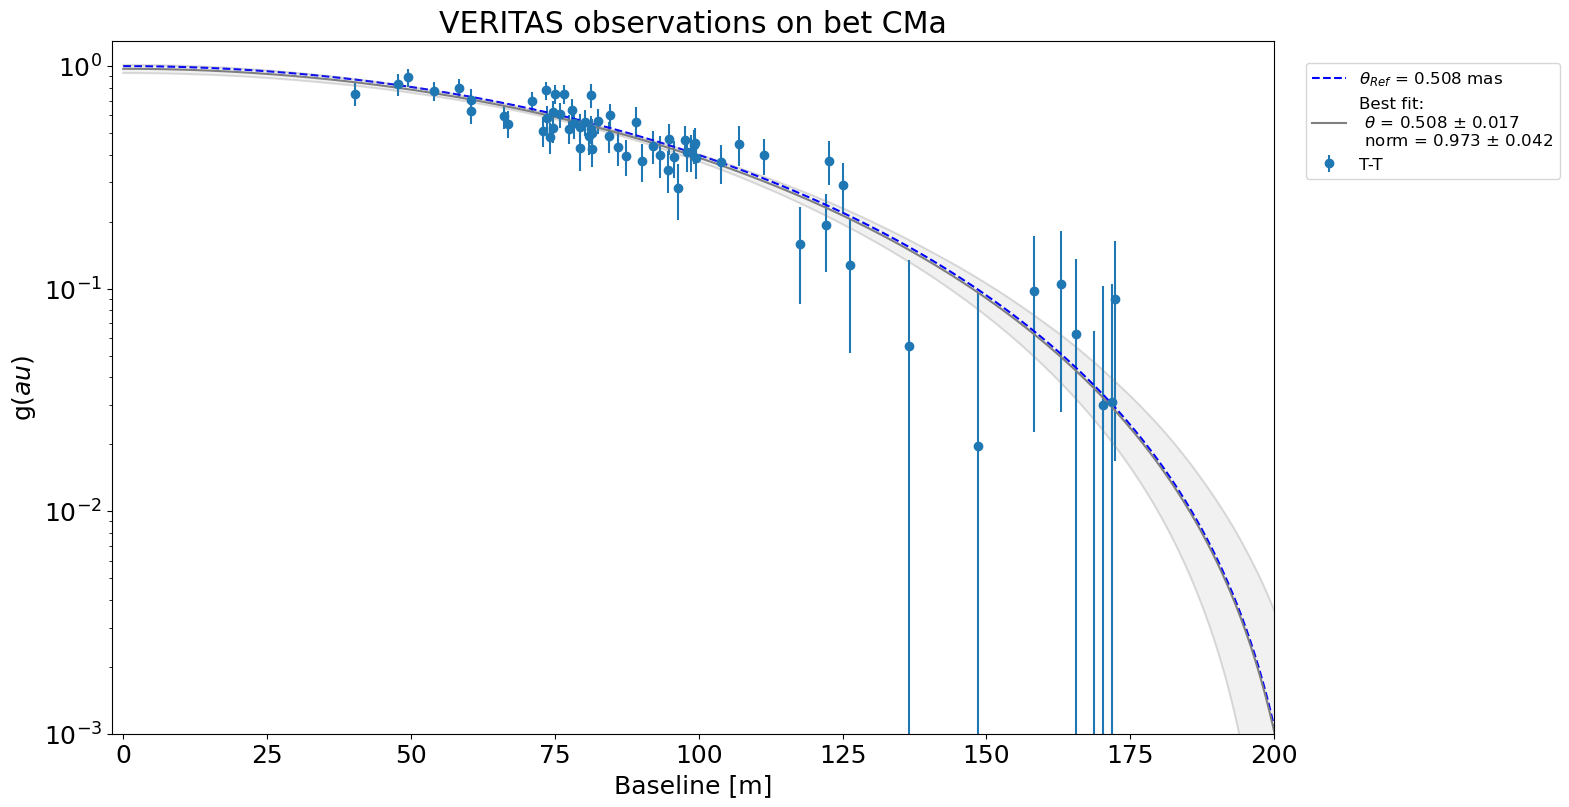

In [3]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("bet CMa", zbc_norm=1., observatory_name="VERITAS")

times = ['2021-01-10T03:00:00',
         '2021-01-10T03:30:00',
         '2021-01-10T04:00:00', 
         '2021-01-10T04:30:00', 
         '2021-01-10T05:00:00', 
         '2021-01-10T05:30:00', 
         '2021-01-10T06:00:00', 
         '2021-01-10T06:30:00', 
         '2021-01-10T07:00:00', 
         '2021-01-10T07:30:00', 
         '2021-01-10T08:00:00']
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=30*u.min, duration_scaling)
# sim_run.simulate_zbc_observations(zbc_time_array, run_duration=30*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)

Closest star found within the JMDC is:
 -Star ids: HD44743 or BET CMA
- Stellar diameter: 0.508


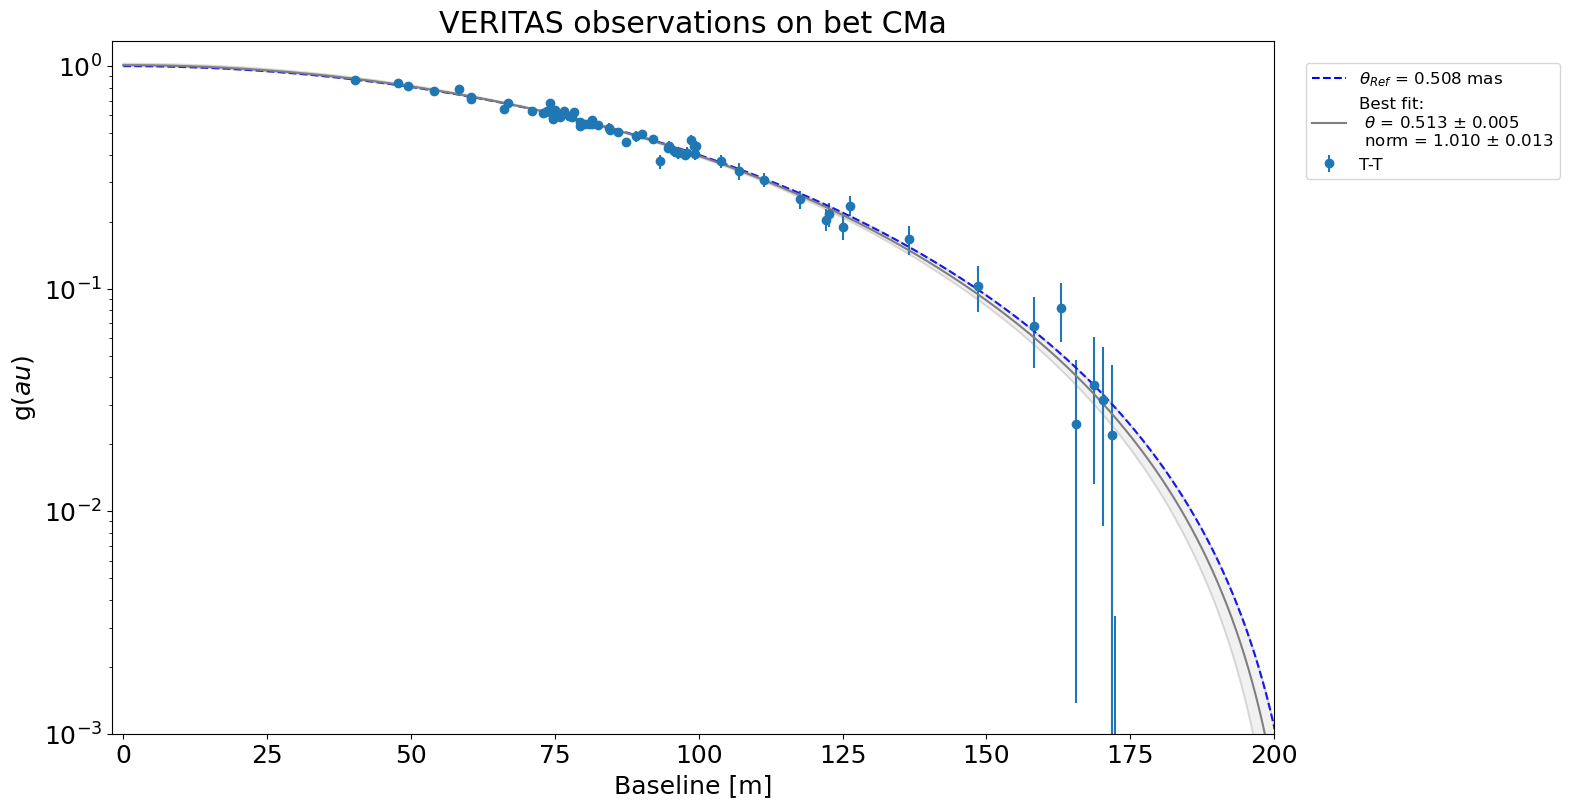

In [4]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("bet CMa", zbc_norm=1., observatory_name="VERITAS")

times = ['2021-01-10T03:00:00',
         '2021-01-10T03:30:00',
         '2021-01-10T04:00:00', 
         '2021-01-10T04:30:00', 
         '2021-01-10T05:00:00', 
         '2021-01-10T05:30:00', 
         '2021-01-10T06:00:00', 
         '2021-01-10T06:30:00', 
         '2021-01-10T07:00:00', 
         '2021-01-10T07:30:00', 
         '2021-01-10T08:00:00']
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=30*u.min, duration_scaling=10.)
# sim_run.simulate_zbc_observations(zbc_time_array, run_duration=30*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)

Closest star found within the JMDC is:
 -Star ids: HD176437 or GAM LYR
- Stellar diameter: 0.729


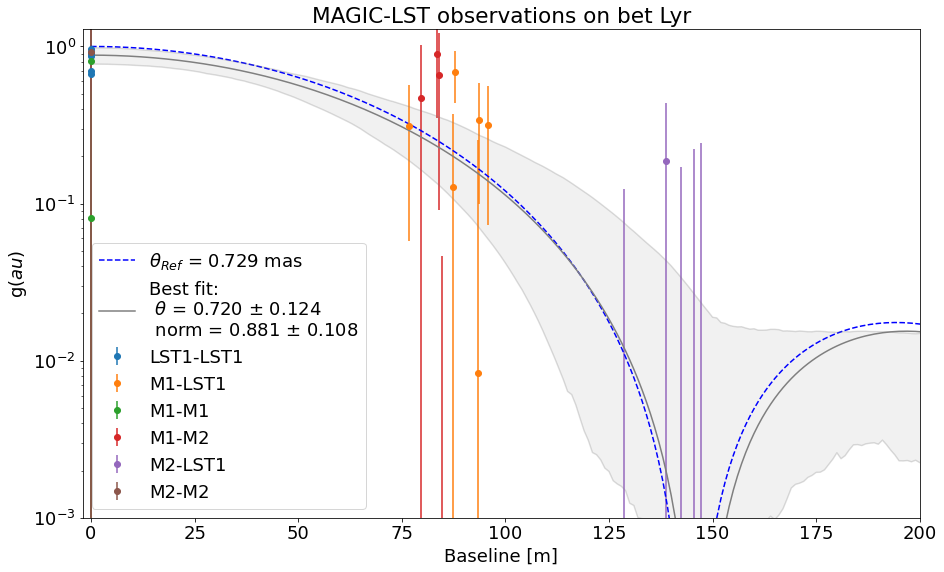

In [7]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("bet Lyr", zbc_norm=1., observatory_name="MAGIC-LST")

times = ['2021-06-16T00:00:00', 
         '2021-06-16T01:00:00', 
         '2021-06-16T02:00:00', 
         '2021-06-16T03:00:00', 
         '2021-06-16T04:00:00', 
         '2021-06-16T05:00:00']
time_array = Time(times, format='isot', scale='utc')
zbc_time_array = Time(times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=30*u.min, moon_to_star_ratio=5)
sim_run.simulate_zbc_observations(zbc_time_array, run_duration=30*u.min, moon_to_star_ratio=5)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)

Closest star found within the JMDC is:
 -Star ids: HD176437 or GAM LYR
- Stellar diameter: 0.729


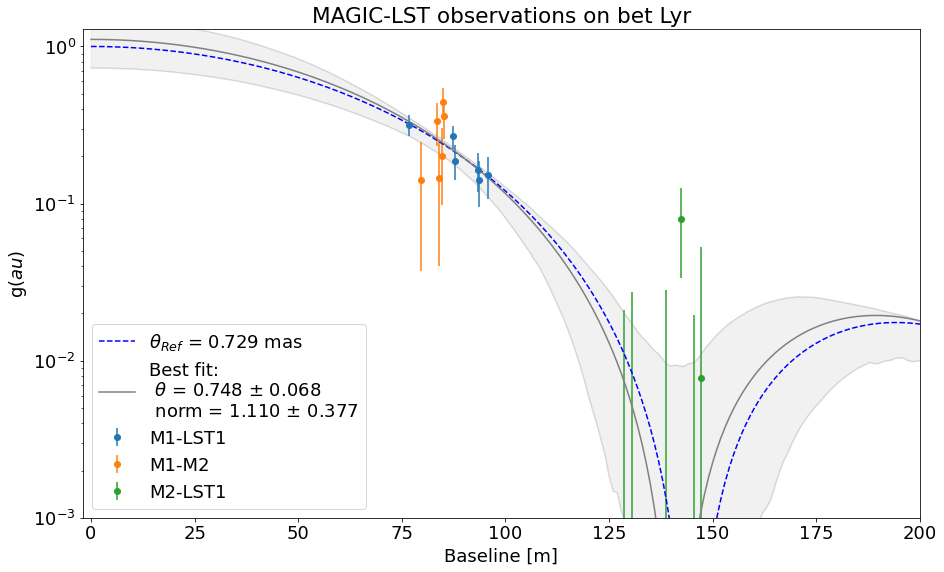

In [8]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("bet Lyr", zbc_norm=1., observatory_name="MAGIC-LST")

times = ['2021-06-16T00:00:00', 
         '2021-06-16T01:00:00', 
         '2021-06-16T02:00:00', 
         '2021-06-16T03:00:00', 
         '2021-06-16T04:00:00', 
         '2021-06-16T05:00:00']
time_array = Time(times, format='isot', scale='utc')
zbc_times = ['2021-06-16T01:30:00', 
             '2021-06-16T02:30:00']
zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=30*u.min, moon_to_star_ratio=0.25/2.)
#sim_run.simulate_zbc_observations(zbc_time_array, run_duration=30*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)

Closest star found within the JMDC is:
 -Star ids: HD157792 or 44 OPH
- Stellar diameter: 0.8
3.05


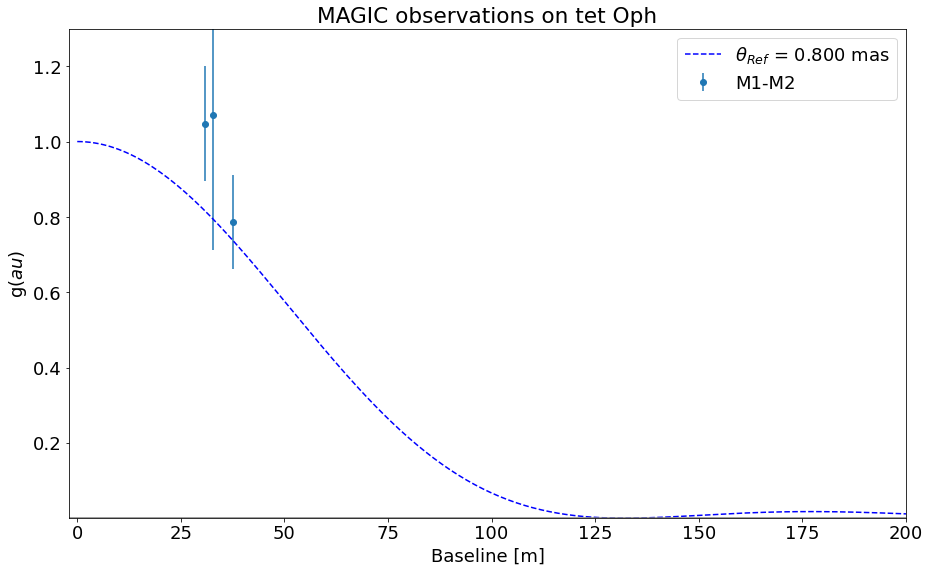

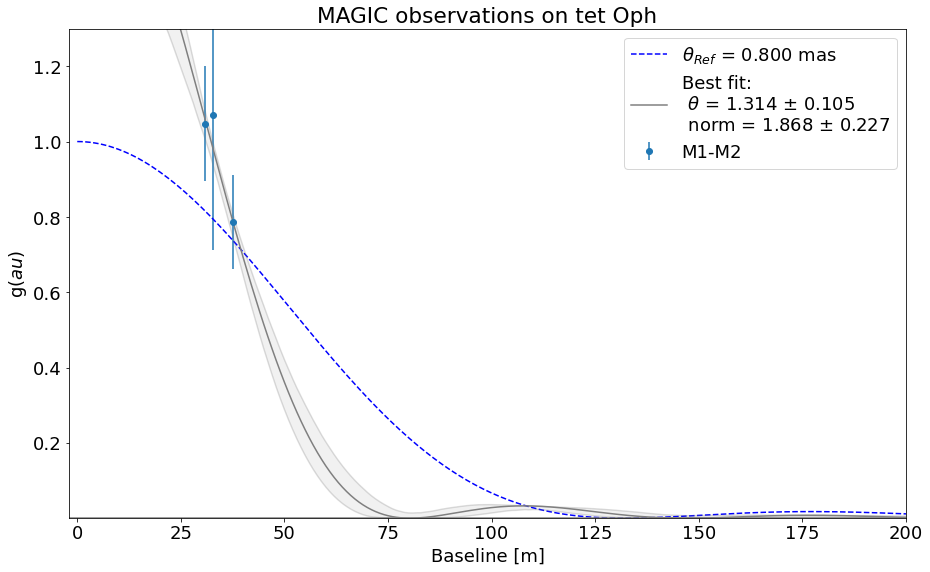

In [9]:
sim_run = SimulateSiiRuns("tet Oph", zbc_norm=1., observatory_name="MAGIC")
times = [
#     '2021-06-10T06:30:00', 
         '2021-06-10T05:30:00', 
         '2021-06-10T04:30:00', 
         '2021-06-10T03:30:00', 
#          '2021-06-10T02:30:00', 
         ]
print(sim_run.target_b_mag)
time_array = Time(times, format='isot', scale='utc')
sim_run.simulate_observations(time_array, run_duration=15*u.min)
sim_run.plot_v2(set_log_yscale=False)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=False)

In [2]:
sim_run = SimulateSiiRuns("nu Eri", zbc_norm=1., observatory_name="MAGIC-LST")
sim_run = SimulateSiiRuns("tet Oph", zbc_norm=1., observatory_name="MAGIC-LST")

Closest star found within the JMDC is:
 -Star ids: HD29391 or HIP21547
- Stellar diameter: 0.518
Closest star found within the JMDC is:
 -Star ids: HD157792 or 44 OPH
- Stellar diameter: 0.8


In [4]:
sim_run = SimulateSiiRuns("alf Vir", zbc_norm=1., observatory_name="MAGIC-LST")
sim_run = SimulateSiiRuns("alf Lyr", zbc_norm=1., observatory_name="MAGIC-LST")
sim_run = SimulateSiiRuns("Deneb", zbc_norm=1., observatory_name="MAGIC-LST")
sim_run = SimulateSiiRuns("Altair", zbc_norm=1., observatory_name="MAGIC-LST")
sim_run = SimulateSiiRuns("Alioth", zbc_norm=1., observatory_name="MAGIC-LST")

Closest star found within the JMDC is:
 -Star ids: HD116658 or ALF VIR
- Stellar diameter: 0.85
Closest star found within the JMDC is:
 -Star ids: HD172167 or ALF LYR
- Stellar diameter: 3.31
Closest star found within the JMDC is:
 -Star ids: HD197345 or ALF CYG
- Stellar diameter: 2.6
Closest star found within the JMDC is:
 -Star ids: HD187642 or ALF AQL
- Stellar diameter: 2.79
Closest star found within the JMDC is:
 -Star ids: HD116842 or Alcor
Closest star found within the JSDC is:
 -Star id: * eps UMa
 -B mag: 1.7380000352859497
 -Spectral type: A1III-IVpkB9

- Expected stellar diameter: 1.449691
- Stellar diameter: 1.449691


Test MAGIC potential on 3 Pup:
=====================

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (115.95195301, -28.95482556)>
Closest star found within the JMDC is:
 -Star ids: HD62412 or --
- Stellar diameter: --


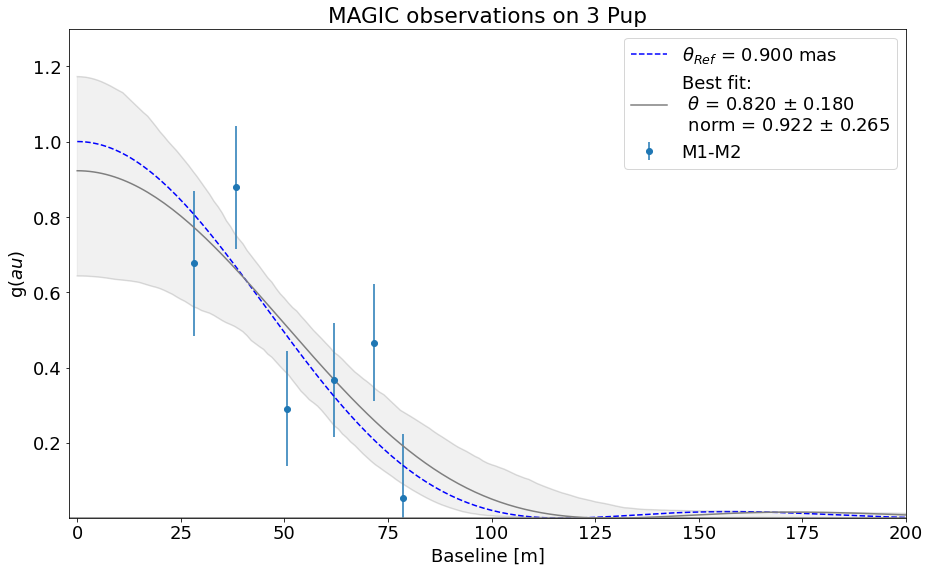

In [9]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("3 Pup", zbc_norm=1., observatory_name="MAGIC")
sim_run.stellar_diameter = 0.9 *u.mas
sim_run.target_b_mag = 4.09
times = ['2021-12-10T01:00:00',
         '2021-12-10T02:00:00',
         '2021-12-10T03:00:00',
         '2021-12-10T04:00:00',
         '2021-12-10T05:00:00',
         '2021-12-10T06:00:00',]
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=60*u.min)
# sim_run.simulate_zbc_observations(time_array, run_duration=60*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=False)
# fit_results = sim_run.uniform_disc_fit
# fit_results['theta_e']/fit_results['theta']


Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (104.65645315, -28.97208616)>
Closest star found within the JMDC is:
 -Star ids: HD52089 or EPS CMA
- Stellar diameter: 0.78


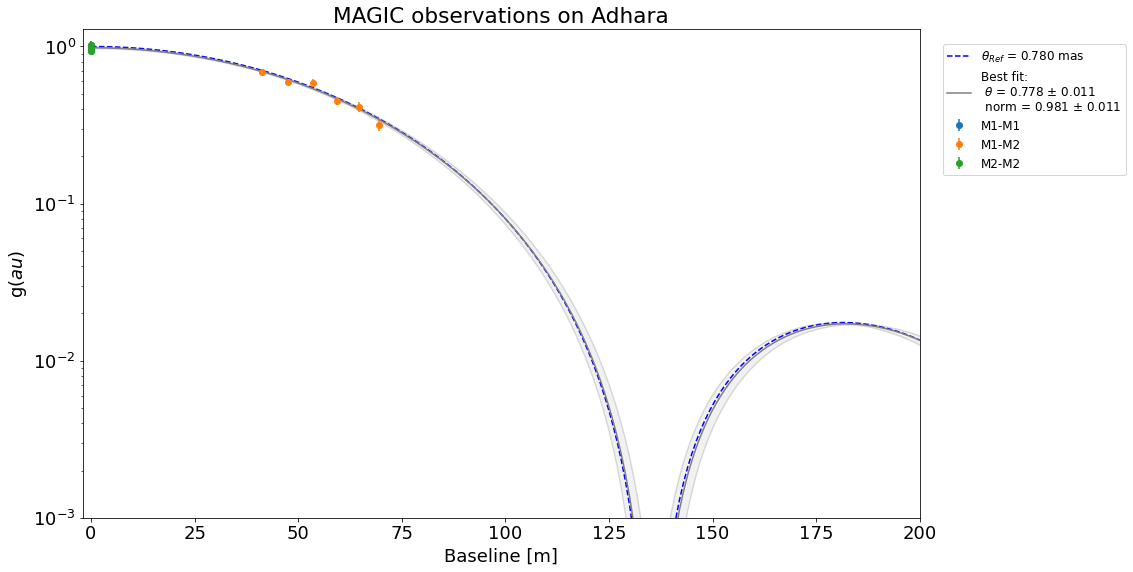

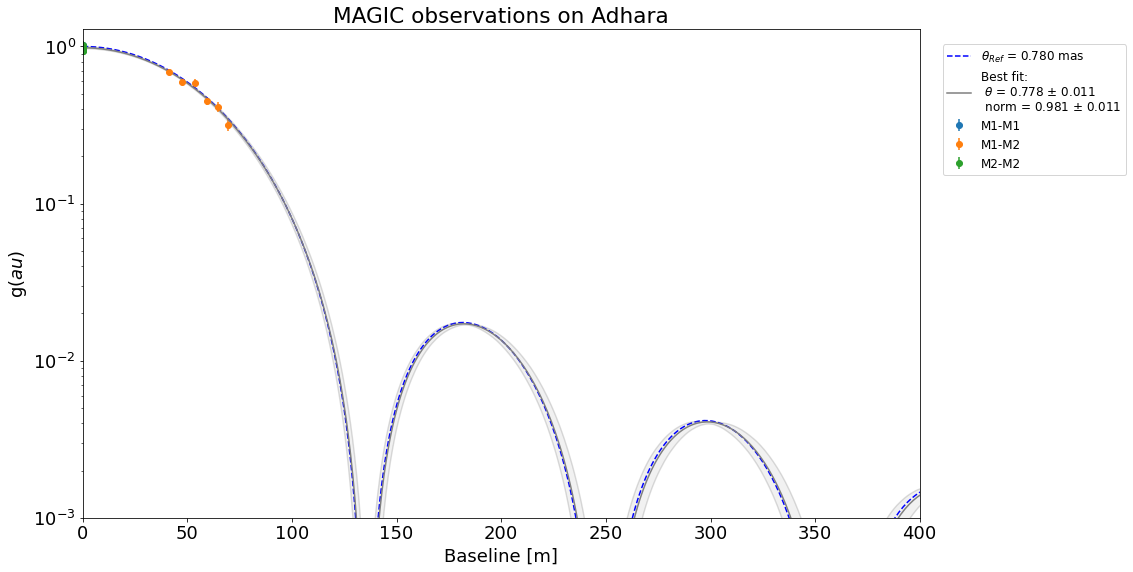

In [5]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("Adhara", zbc_norm=1., observatory_name="MAGIC")

times = ['2021-02-22T21:00:00', 
         '2021-02-22T21:30:00', 
         '2021-02-22T22:00:00', 
         '2021-02-22T22:30:00', 
         '2021-02-22T23:00:00', 
         '2021-02-22T23:30:00']
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.simulate_zbc_observations(time_array, run_duration=10*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
sim_run.f.get_axes()[0].set_xlim([0, 400])
sim_run.f

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (104.65645315, -28.97208616)>
Closest star found within the JMDC is:
 -Star ids: HD52089 or EPS CMA
- Stellar diameter: 0.78


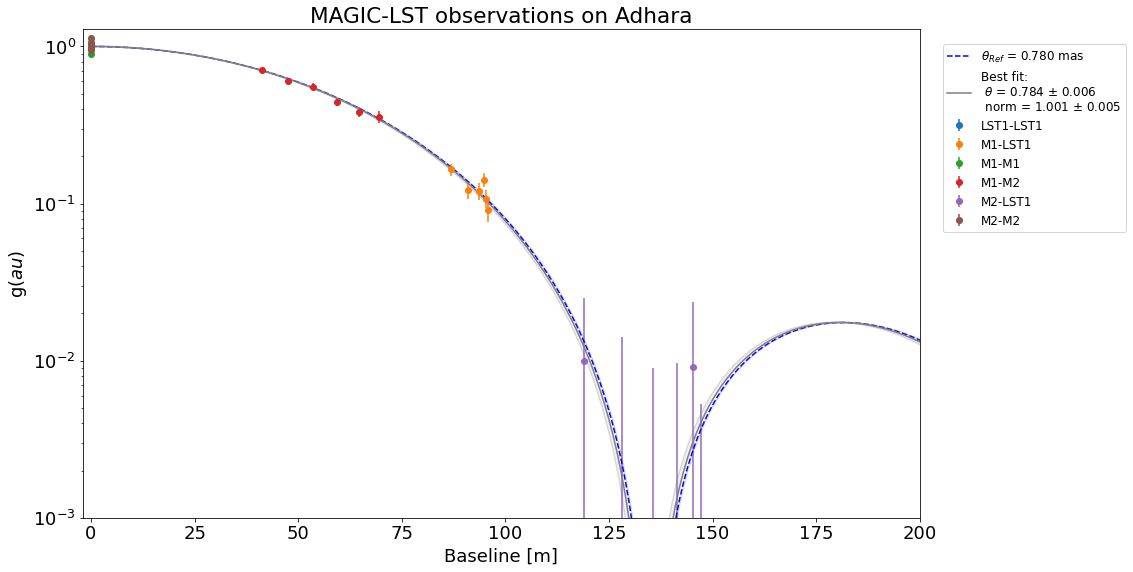

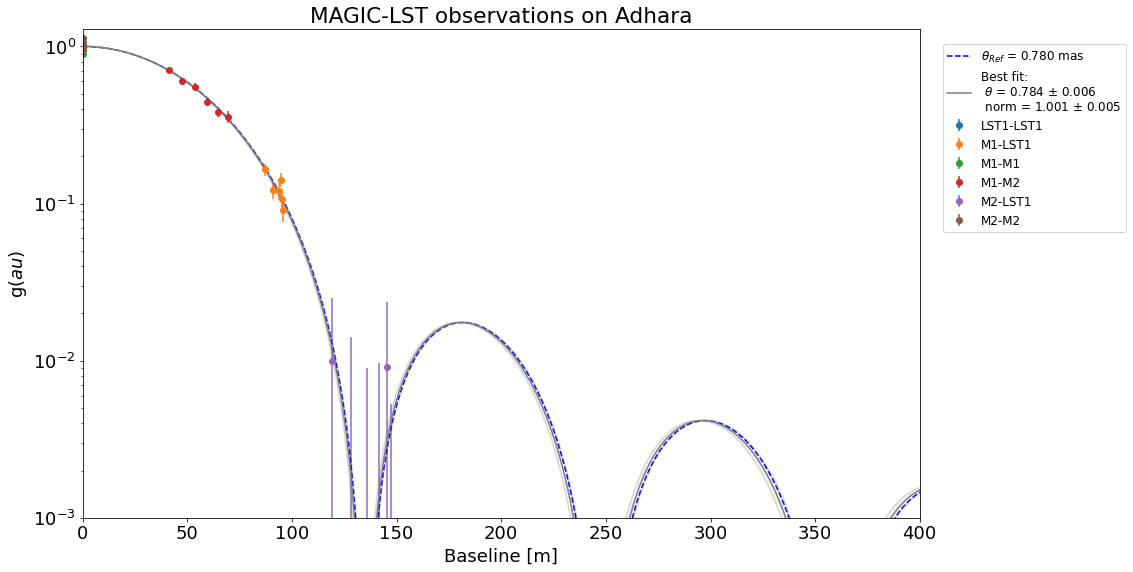

In [6]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("Adhara", zbc_norm=1., observatory_name="MAGIC-LST")

times = ['2021-02-22T21:00:00', 
         '2021-02-22T21:30:00', 
         '2021-02-22T22:00:00', 
         '2021-02-22T22:30:00', 
         '2021-02-22T23:00:00', 
         '2021-02-22T23:30:00']
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.simulate_zbc_observations(time_array, run_duration=10*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
sim_run.f.get_axes()[0].set_xlim([0, 400])
sim_run.f

In [2]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("Adhara", zbc_norm=1., observatory_name="MAGIC-4LST")

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (104.65645315, -28.97208616)>
Closest star found within the JMDC is:
 -Star ids: HD52089 or EPS CMA
- Stellar diameter: 0.78


Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (104.65645315, -28.97208616)>
Closest star found within the JMDC is:
 -Star ids: HD52089 or EPS CMA
- Stellar diameter: 0.78


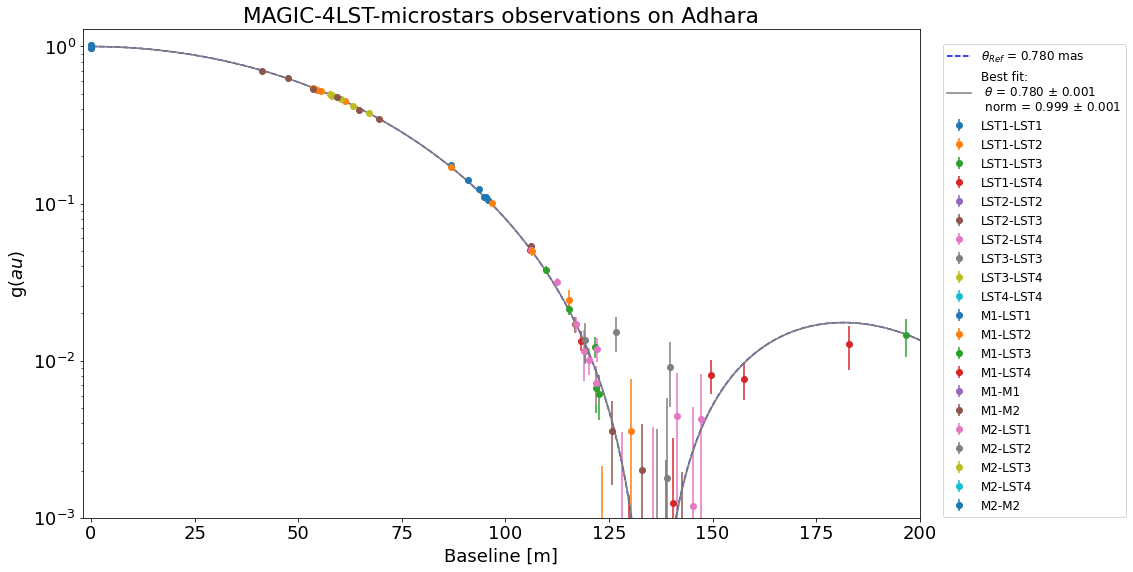

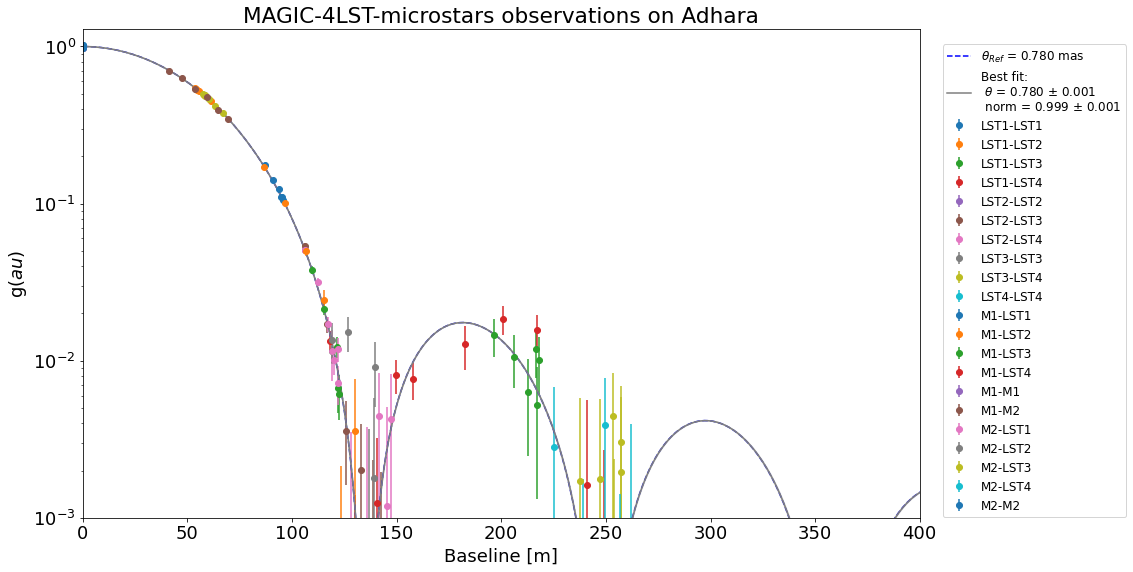

In [21]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("Adhara", zbc_norm=1., observatory_name="MAGIC-4LST-microstars")

times = ['2021-02-22T21:00:00', 
         '2021-02-22T21:30:00', 
         '2021-02-22T22:00:00', 
         '2021-02-22T22:30:00', 
         '2021-02-22T23:00:00', 
         '2021-02-22T23:30:00']
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.simulate_zbc_observations(time_array, run_duration=10*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
sim_run.f.get_axes()[0].set_xlim([0, 400])
sim_run.f

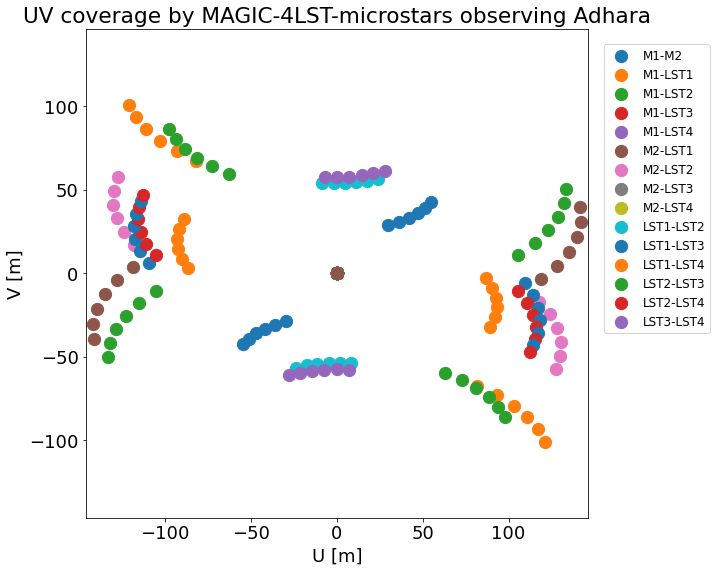

In [22]:
sim_run.plot_uv()

/home/thassan/Paquetes/last_version/magic_spysii/magic_spysii/sim_run.py:353: SyntaxWarning: "is" with a literal. Did you mean "=="?
  if k is 0:


Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (104.65645315, -28.97208616)>
Closest star found within the JMDC is:
 -Star ids: HD52089 or EPS CMA
- Stellar diameter: 0.78


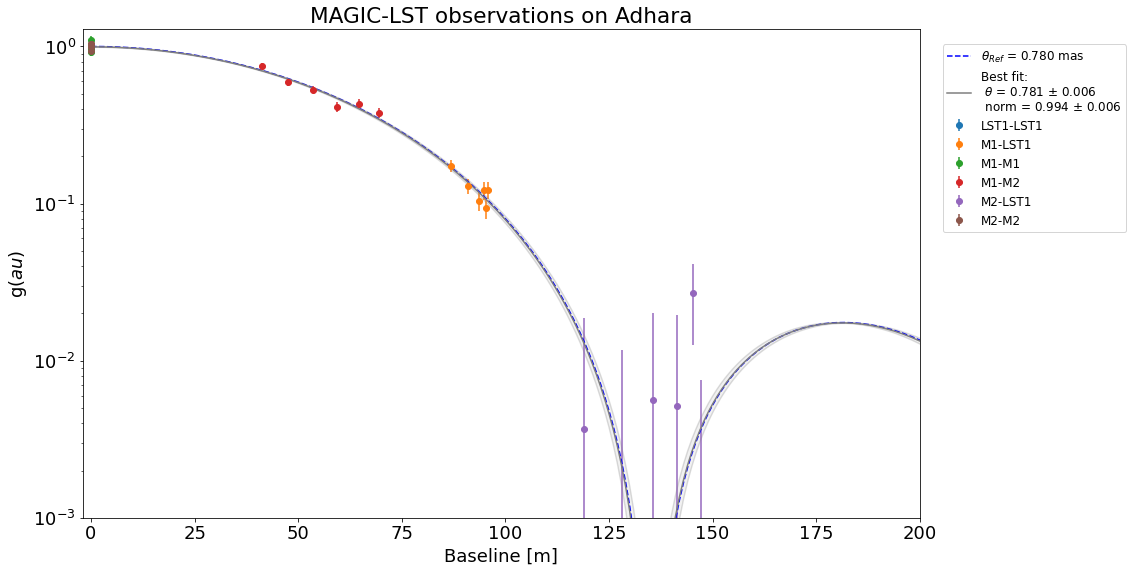

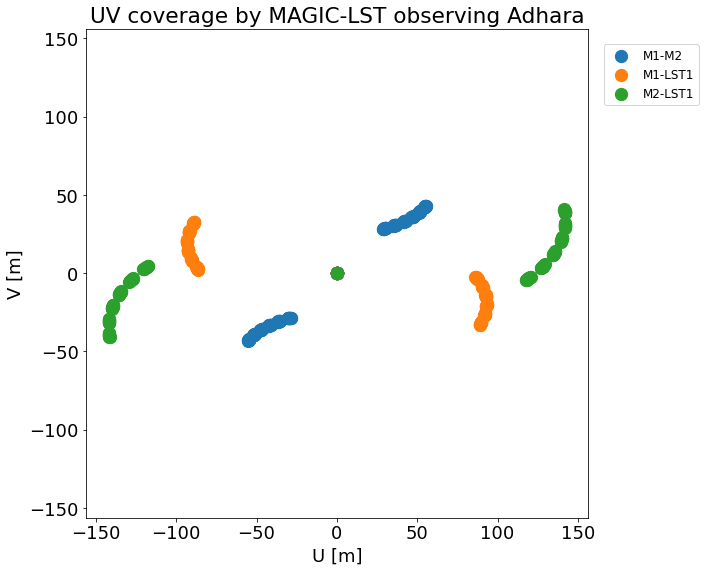

In [1]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("Adhara", zbc_norm=1., observatory_name="MAGIC-LST")

times = ['2021-02-22T21:00:00', 
         '2021-02-22T21:30:00', 
         '2021-02-22T22:00:00', 
         '2021-02-22T22:30:00', 
         '2021-02-22T23:00:00', 
         '2021-02-22T23:30:00']
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.simulate_zbc_observations(time_array, run_duration=10*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
sim_run.f.get_axes()[0].set_xlim([0, 400])
sim_run.f
sim_run.plot_uv()

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (104.65645315, -28.97208616)>
Closest star found within the JMDC is:
 -Star ids: HD52089 or EPS CMA
- Stellar diameter: 0.78


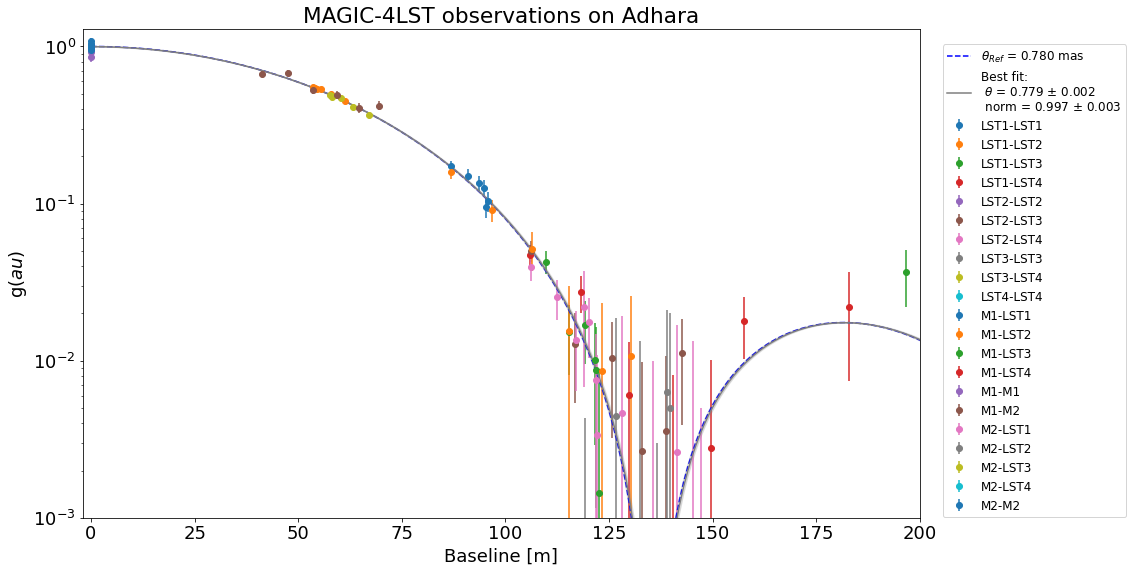

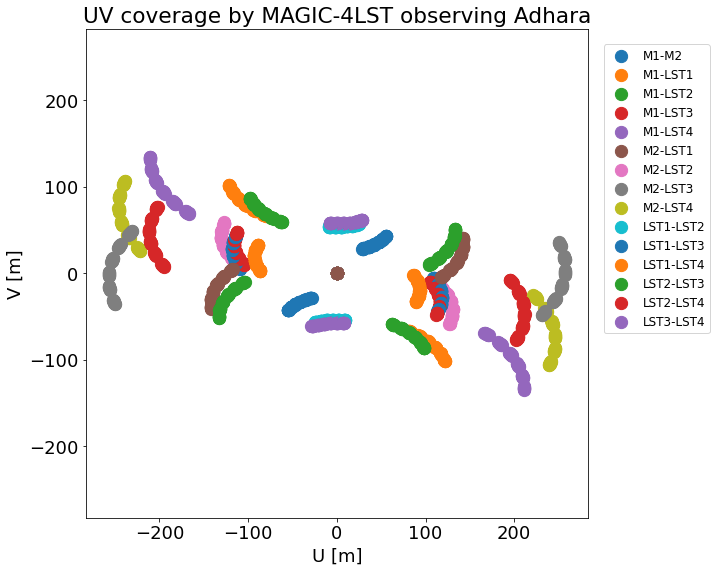

In [2]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("Adhara", zbc_norm=1., observatory_name="MAGIC-4LST")

times = ['2021-02-22T21:00:00', 
         '2021-02-22T21:30:00', 
         '2021-02-22T22:00:00', 
         '2021-02-22T22:30:00', 
         '2021-02-22T23:00:00', 
         '2021-02-22T23:30:00']
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.simulate_zbc_observations(time_array, run_duration=10*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
sim_run.f.get_axes()[0].set_xlim([0, 400])
sim_run.f
sim_run.plot_uv()

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (152.09296244, 11.96720878)>
Closest star found within the JMDC is:
 -Star ids: HD87901 or ALF LEO
- Stellar diameter: 1.33


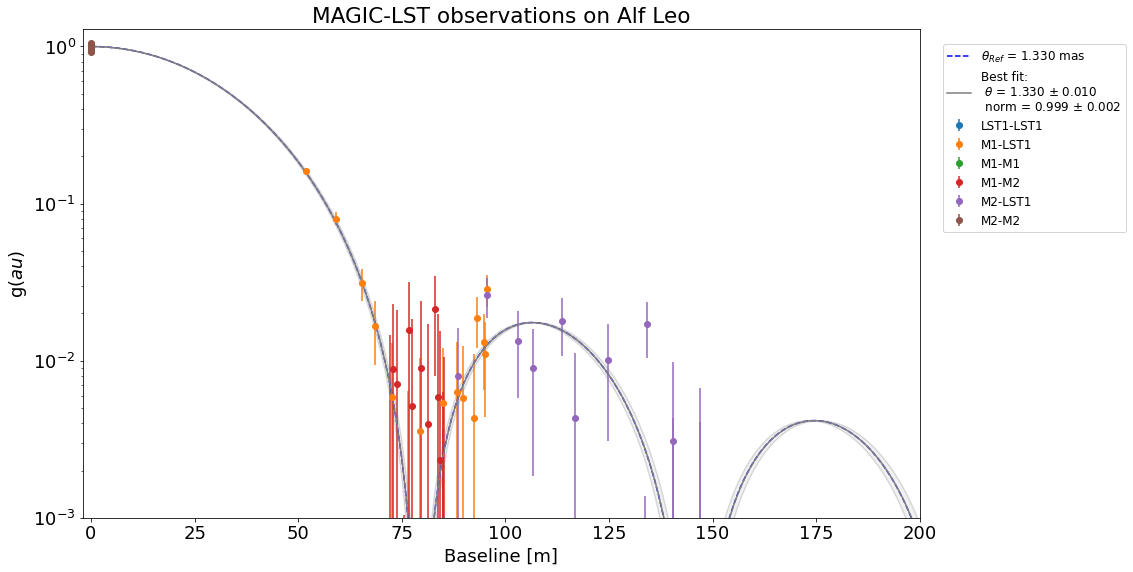

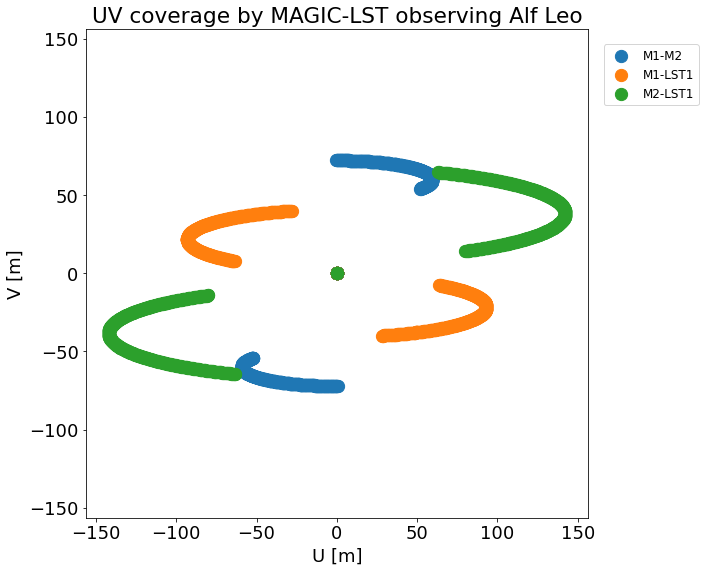

In [3]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("Alf Leo", zbc_norm=1., observatory_name="MAGIC-LST")
# sim_run = SimulateSiiRuns("Alf Leo", zbc_norm=1., observatory_name="MAGIC-4LST-microstars")

times = ['2022-01-20T23:00:00', 
         '2022-01-20T23:30:00', 
         '2022-01-20T00:00:00', 
         '2022-01-20T00:30:00', 
         '2022-01-20T01:00:00', 
         '2022-01-20T01:30:00', 
         '2022-01-20T02:00:00', 
         '2022-01-20T02:30:00', 
         '2022-01-20T03:00:00', 
         '2022-01-20T03:30:00', 
         '2022-01-20T04:00:00', 
         '2022-01-20T04:30:00',
         '2022-01-20T05:00:00', 
         '2022-01-20T05:30:00', 
         '2022-01-20T06:00:00', 
         '2022-01-20T06:30:00',
#         '2022-01-21T23:00:00', 
#          '2022-01-21T23:30:00', 
#          '2022-01-21T00:00:00', 
#          '2022-01-21T00:30:00', 
#          '2022-01-21T01:00:00', 
#          '2022-01-21T01:30:00', 
#          '2022-01-21T02:00:00', 
#          '2022-01-21T02:30:00', 
#          '2022-01-21T03:00:00', 
#          '2022-01-21T03:30:00', 
#          '2022-01-21T04:00:00', 
#          '2022-01-21T04:30:00',
#          '2022-01-21T05:00:00', 
#          '2022-01-21T05:30:00', 
#          '2022-01-21T06:00:00', 
#          '2022-01-21T06:30:00',
#         '2022-01-22T23:00:00', 
#          '2022-01-22T23:30:00', 
#          '2022-01-22T00:00:00', 
#          '2022-01-22T00:30:00', 
#          '2022-01-22T01:00:00', 
#          '2022-01-22T01:30:00', 
#          '2022-01-22T02:00:00', 
#          '2022-01-22T02:30:00', 
#          '2022-01-22T03:00:00', 
#          '2022-01-22T03:30:00', 
#          '2022-01-22T04:00:00', 
#          '2022-01-22T04:30:00',
#          '2022-01-22T05:00:00', 
#          '2022-01-22T05:30:00', 
#          '2022-01-22T06:00:00', 
#          '2022-01-22T06:30:00',
#         '2022-01-23T23:00:00', 
#          '2022-01-23T23:30:00', 
#          '2022-01-23T00:00:00', 
#          '2022-01-23T00:30:00', 
#          '2022-01-23T01:00:00', 
#          '2022-01-23T01:30:00', 
#          '2022-01-23T02:00:00', 
#          '2022-01-23T02:30:00', 
#          '2022-01-23T03:00:00', 
#          '2022-01-23T03:30:00', 
#          '2022-01-23T04:00:00', 
#          '2022-01-23T04:30:00',
#          '2022-01-23T05:00:00', 
#          '2022-01-23T05:30:00', 
#          '2022-01-23T06:00:00', 
#          '2022-01-23T06:30:00',
        ]
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=30*u.min)
sim_run.simulate_zbc_observations(time_array, run_duration=30*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
sim_run.f.get_axes()[0].set_xlim([0, 400])
sim_run.f
sim_run.plot_uv()

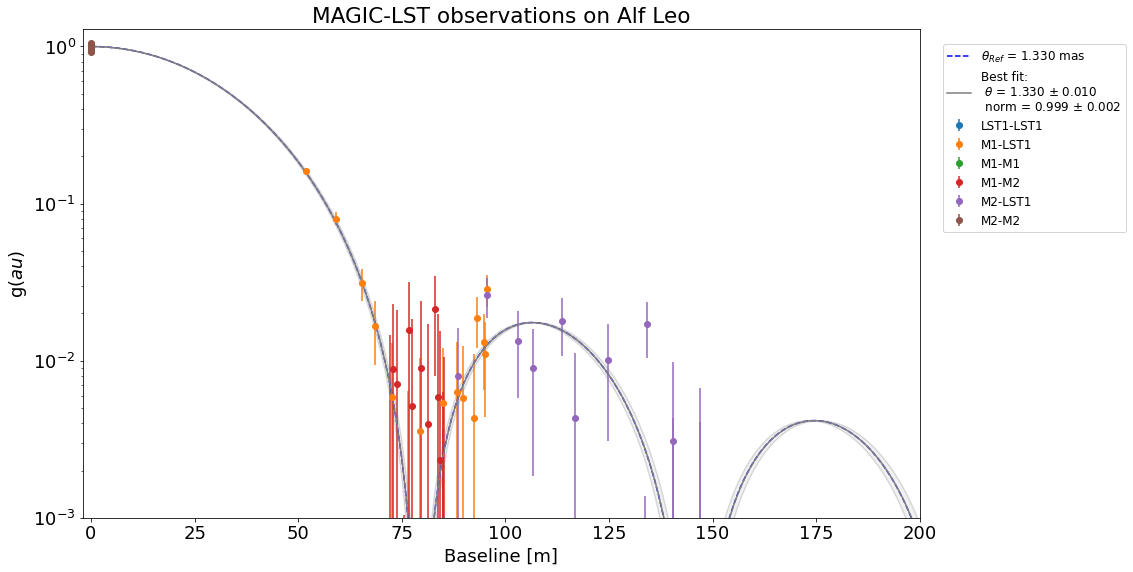

In [4]:
%matplotlib inline
sim_run.plot_v2(set_log_yscale=True)

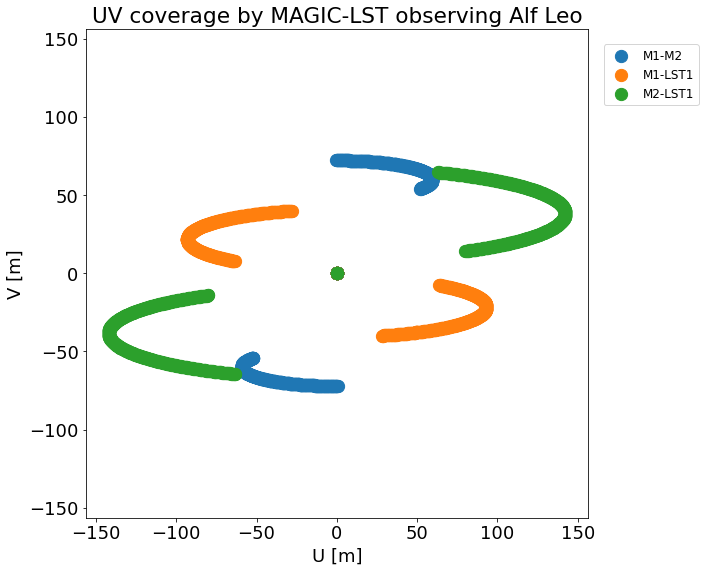

In [5]:
sim_run.plot_uv()

ERROR:root:The altitude of the source at the time 2022-02-24T02:17:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2022-02-24T02:18:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2022-02-24T02:19:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2022-02-24T02:20:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2022-02-24T02:21:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2022-02-24T02:22:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2022-02-24T02:23:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2022-02-24T02:24:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2022-02-24T02:25:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2022-02-24T02:26:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2022-02-24T02:27:00.000 is just too low.

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (104.65645315, -28.97208616)>
Closest star found within the JMDC is:
 -Star ids: HD52089 or EPS CMA
- Stellar diameter: 0.78


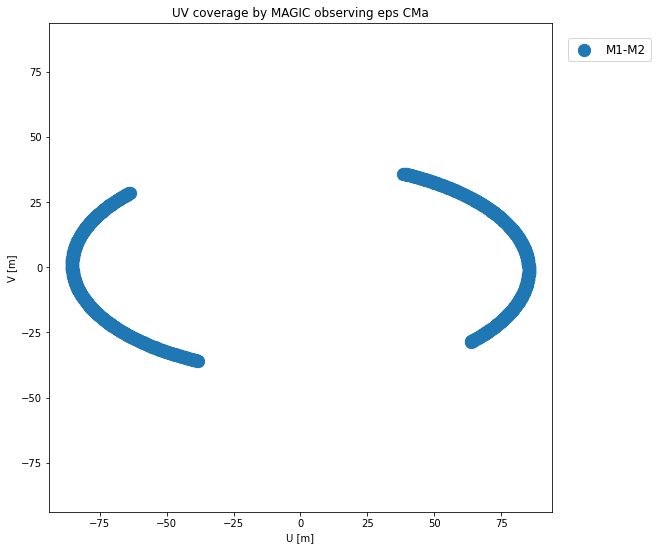

In [13]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("eps CMa", zbc_norm=1., observatory_name="MAGIC")
# sim_run = SimulateSiiRuns("Alf Leo", zbc_norm=1., observatory_name="MAGIC-4LST-microstars")

times = ['2022-02-23T20:00:00', 
        ]
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=60*7*u.min)
# sim_run.simulate_zbc_observations(time_array, run_duration=30*u.min)

# sim_run.plot_v2(set_log_yscale=True)
# sim_run.fit_uniform_disc()
# sim_run.plot_v2(set_log_yscale=True)
sim_run.plot_uv()

In [10]:
import astropy.units as u
import numpy as np
from astropy.time import Time
from astropy.coordinates import SkyCoord, EarthLocation, AltAz, HADec
epsCMa = SkyCoord.from_name("eps CMa")
time = Time('2022-2-23 00:00:00')
hadec_frame = HADec(obstime=time, location=sim_run.site)
m33_hadec_frame = epsCMa.transform_to(hadec_frame)
np.cos(m33_hadec_frame.ha.rad)

In [4]:
m33 = SkyCoord.from_name('M33')
bear_mountain = EarthLocation(lat=41.3*u.deg, lon=-74*u.deg, height=390*u.m)
utcoffset = -4*u.hour  # Eastern Daylight Time
time = Time('2012-7-12 23:00:00') - utcoffset

m33altaz = m33.transform_to(AltAz(obstime=time,location=bear_mountain))
print(f"M33's Altitude = {m33altaz.alt:.2}")

midnight = Time('2012-7-13 00:00:00') - utcoffset
delta_midnight = np.linspace(-2, 10, 100)*u.hour
frame_July13night = AltAz(obstime=midnight+delta_midnight,
                          location=bear_mountain)
m33altazs_July13night = m33.transform_to(frame_July13night)

M33's Altitude = 0.13 deg


In [5]:
import astropy
astropy.__version__

'5.0.1'

In [6]:
m33 = SkyCoord.from_name('M33')
bear_mountain = EarthLocation(lat=41.3*u.deg, lon=-74*u.deg, height=390*u.m)
utcoffset = -4*u.hour  # Eastern Daylight Time
time = Time('2012-7-12 23:00:00') - utcoffset

m33altaz = m33.transform_to(AltAz(obstime=time,location=bear_mountain))
print(f"M33's Altitude = {m33altaz.alt:.2}")

midnight = Time('2012-7-13 00:00:00') - utcoffset
delta_midnight = np.linspace(-2, 10, 100)*u.hour
hadec_frame = HADec(obstime=midnight+delta_midnight,
                          location=bear_mountain)
m33_hadec_frame = m33.transform_to(hadec_frame)

M33's Altitude = 0.13 deg


In [7]:
midnight+delta_midnight

<Time object: scale='utc' format='iso' value=['2012-07-13 02:00:00.000' '2012-07-13 02:07:16.364'
 '2012-07-13 02:14:32.727' '2012-07-13 02:21:49.091'
 '2012-07-13 02:29:05.455' '2012-07-13 02:36:21.818'
 '2012-07-13 02:43:38.182' '2012-07-13 02:50:54.545'
 '2012-07-13 02:58:10.909' '2012-07-13 03:05:27.273'
 '2012-07-13 03:12:43.636' '2012-07-13 03:20:00.000'
 '2012-07-13 03:27:16.364' '2012-07-13 03:34:32.727'
 '2012-07-13 03:41:49.091' '2012-07-13 03:49:05.455'
 '2012-07-13 03:56:21.818' '2012-07-13 04:03:38.182'
 '2012-07-13 04:10:54.545' '2012-07-13 04:18:10.909'
 '2012-07-13 04:25:27.273' '2012-07-13 04:32:43.636'
 '2012-07-13 04:40:00.000' '2012-07-13 04:47:16.364'
 '2012-07-13 04:54:32.727' '2012-07-13 05:01:49.091'
 '2012-07-13 05:09:05.455' '2012-07-13 05:16:21.818'
 '2012-07-13 05:23:38.182' '2012-07-13 05:30:54.545'
 '2012-07-13 05:38:10.909' '2012-07-13 05:45:27.273'
 '2012-07-13 05:52:43.636' '2012-07-13 06:00:00.000'
 '2012-07-13 06:07:16.364' '2012-07-13 06:14:32.727'
 

In [9]:
np.cos(m33_hadec_frame.ha.rad)

array([-0.72272701, -0.70037291, -0.67730972, -0.65356081, -0.62915021,
       -0.60410263, -0.57844344, -0.55219862, -0.52539474, -0.49805893,
       -0.47021886, -0.44190274, -0.41313922, -0.38395742, -0.3543869 ,
       -0.32445758, -0.29419977, -0.26364411, -0.23282152, -0.20176323,
       -0.17050066, -0.13906547, -0.10748949, -0.07580468, -0.04404313,
       -0.01223699,  0.01958154,  0.05138024,  0.08312692,  0.11478944,
        0.14633575,  0.1777339 ,  0.2089521 ,  0.23995875,  0.27072246,
        0.30121208,  0.33139674,  0.36124589,  0.3907293 ,  0.41981712,
        0.4484799 ,  0.47668863,  0.50441475,  0.53163017,  0.55830736,
        0.5844193 ,  0.60993956,  0.63484229,  0.65910229,  0.682695  ,
        0.70559652,  0.72778367,  0.74923399,  0.76992577,  0.78983804,
        0.80895067,  0.82724428,  0.84470036,  0.86130125,  0.87703013,
        0.89187107,  0.90580905,  0.91882997,  0.93092063,  0.9420688 ,
        0.95226319,  0.96149348,  0.96975032,  0.97702536,  0.98

Closest star found within the JMDC is:
 -Star ids: HD44743 or BET CMA
- Stellar diameter: 0.508


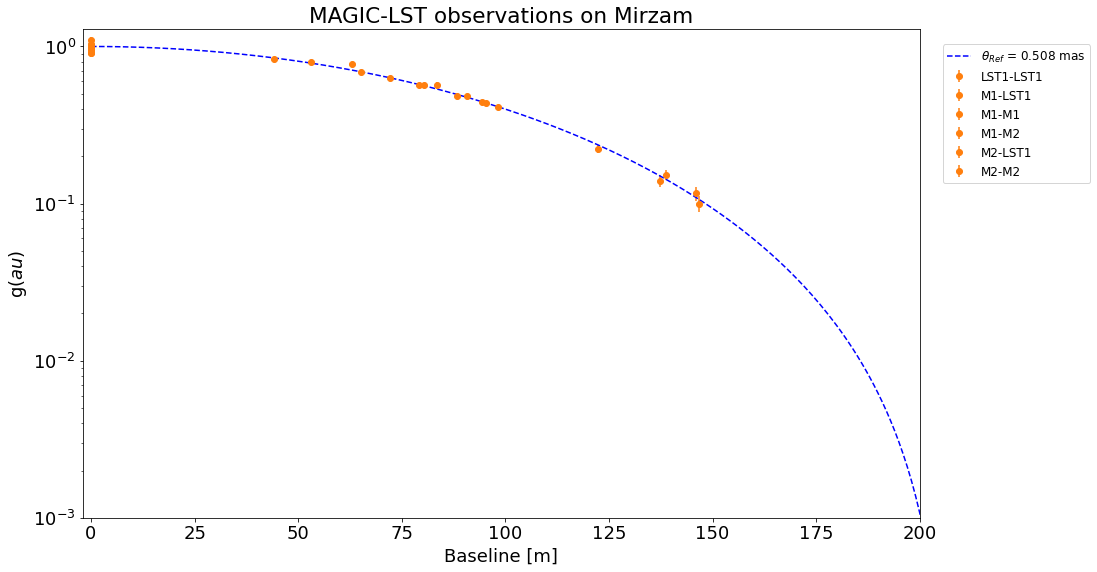

In [7]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("Mirzam", zbc_norm=1., observatory_name="MAGIC-LST")


times = ['2022-2-1T20:00:00', 
         '2022-2-1T21:00:00',
         '2022-2-1T22:00:00',
         '2022-2-1T23:00:00',
         '2022-2-2T00:00:00',
         '2022-2-2T01:00:00']
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=30*u.min)
sim_run.simulate_zbc_observations(time_array, run_duration=30*u.min)

sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
sim_run.f
sim_run.plot_uv()
sim_run.f.get_axes()[0].set_xlim([0, 400])

Closest star found within the JMDC is:
 -Star ids: HD116658 or ALF VIR
- Stellar diameter: 0.85
0.75


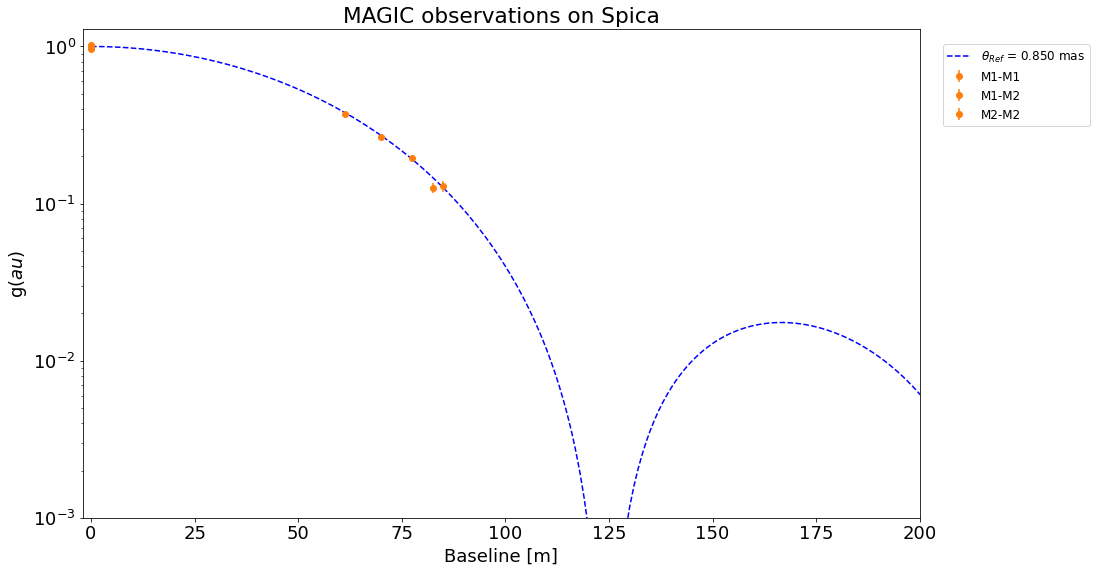

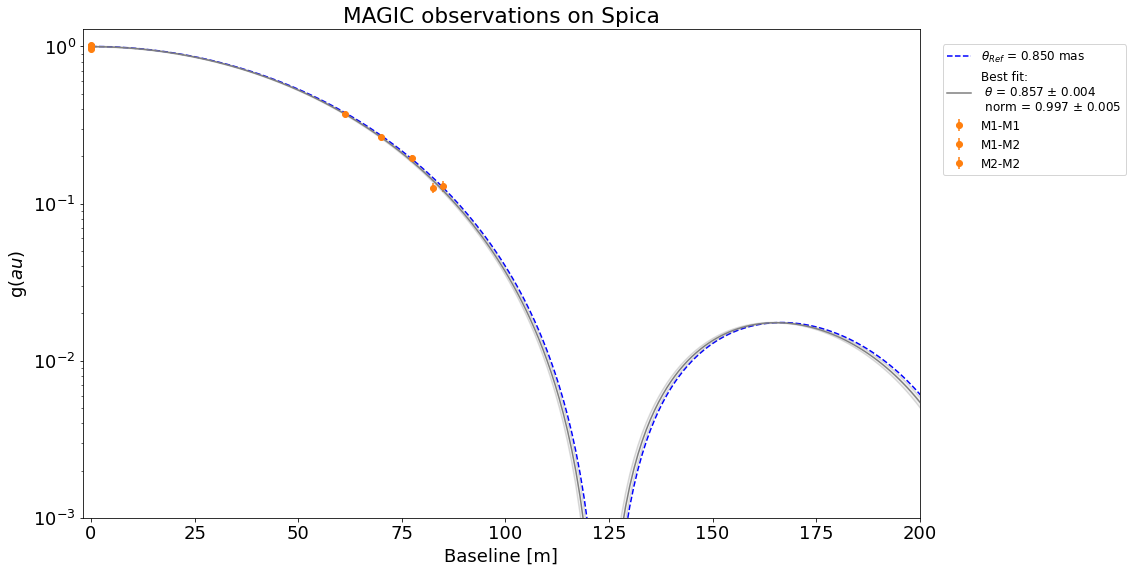

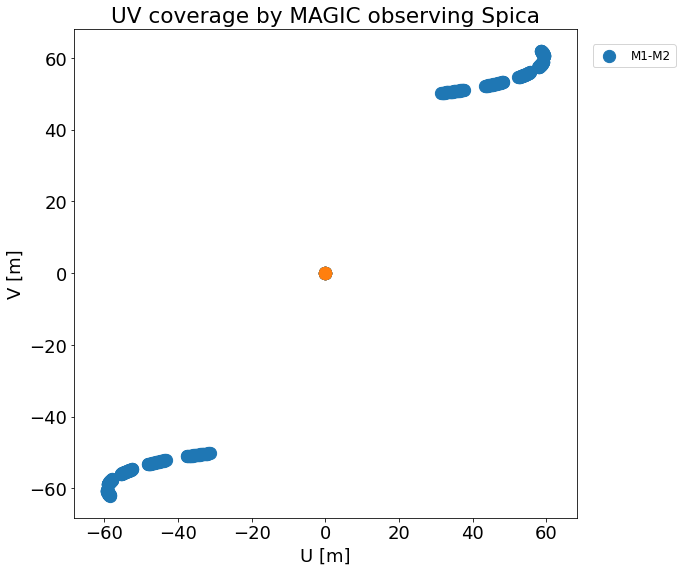

(0.0, 400.0)

In [11]:

import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("Spica", zbc_norm=1., observatory_name="MAGIC")

print(sim_run.target_b_mag)

times = ['2022-3-1T01:00:00', 
         '2022-3-1T02:00:00', 
         '2022-3-1T03:00:00', 
         '2022-3-1T04:00:00', 
         '2022-3-1T05:00:00', 
         ]
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=30*u.min)
sim_run.simulate_zbc_observations(time_array, run_duration=30*u.min)

sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
sim_run.f
sim_run.plot_uv()
sim_run.f.get_axes()[0].set_xlim([0, 400])

Simulating iot Cap:
------------------

ERROR:root:The altitude of the source at the time 2023-09-01T04:53:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T04:54:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T04:55:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T04:56:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T04:57:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T04:58:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T04:59:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:00:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:01:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:02:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:03:00.000 is just too low.

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (320.56164853, -16.83454439)>
Closest star found within the JMDC is:
 -Star ids: HD200994 or RS CAP
- Stellar diameter: 7.75
5.18


ERROR:root:The altitude of the source at the time 2023-09-01T06:06:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:07:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:08:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:09:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:10:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:11:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:12:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:13:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:14:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:15:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:16:00.000 is just too low.

ERROR:root:The altitude of the source at the time 2023-09-01T06:10:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:11:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:12:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:13:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:14:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:15:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:16:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:17:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:18:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:19:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T06:20:00.000 is just too low.

ERROR:root:The altitude of the source at the time 2023-09-01T05:14:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:15:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:16:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:17:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:18:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:19:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:20:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:21:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:22:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:23:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:24:00.000 is just too low.

...

ERROR:root:The altitude of the source at the time 2023-09-01T09:28:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T09:29:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T09:30:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T09:31:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T09:32:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T09:33:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T09:34:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T09:35:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T09:36:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T09:37:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T09:38:00.000 is just too low.

ERROR:root:The altitude of the source at the time 2023-09-01T05:32:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:33:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:34:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:35:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:36:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:37:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:38:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:39:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:40:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:41:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T05:42:00.000 is just too low.

ERROR:root:The altitude of the source at the time 2023-09-01T07:03:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T07:04:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T07:05:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T07:06:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T07:07:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T07:08:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T07:09:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T07:10:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T07:11:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T07:12:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T07:13:00.000 is just too low.

ERROR:root:The altitude of the source at the time 2023-09-01T08:34:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T08:35:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T08:36:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T08:37:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T08:38:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T08:39:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T08:40:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T08:41:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T08:42:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T08:43:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T08:44:00.000 is just too low.

ERROR:root:The altitude of the source at the time 2023-09-01T10:05:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T10:06:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T10:07:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T10:08:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T10:09:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T10:10:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T10:11:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T10:12:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T10:13:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T10:14:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2023-09-01T10:15:00.000 is just too low.

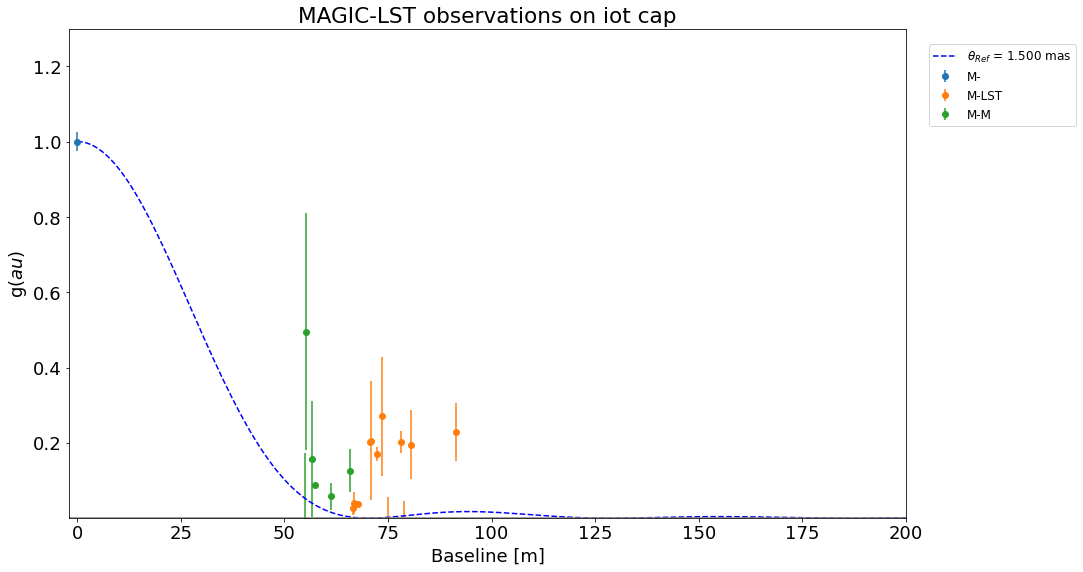

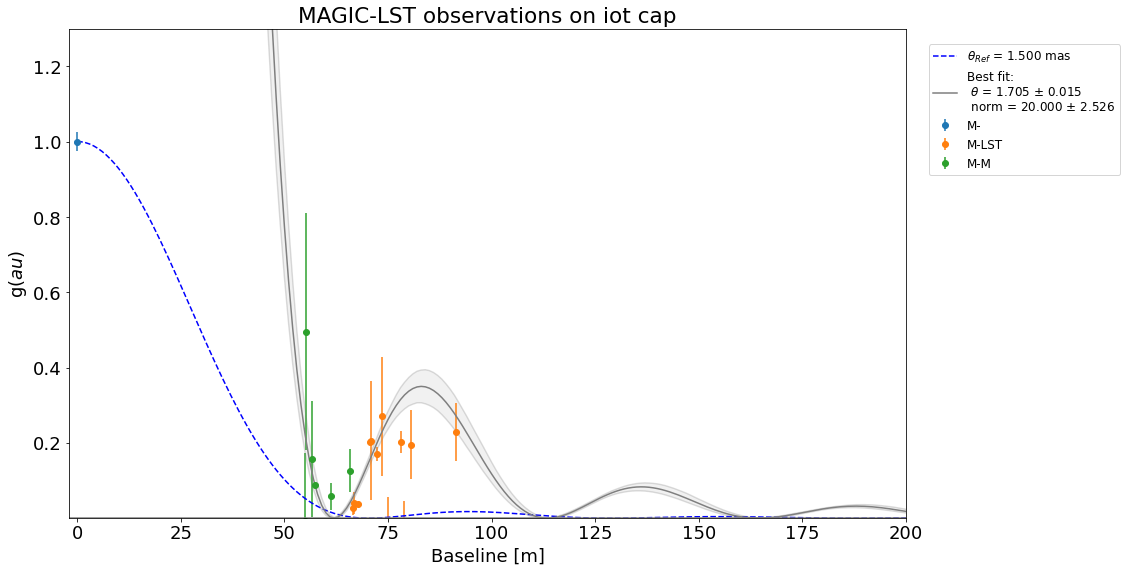

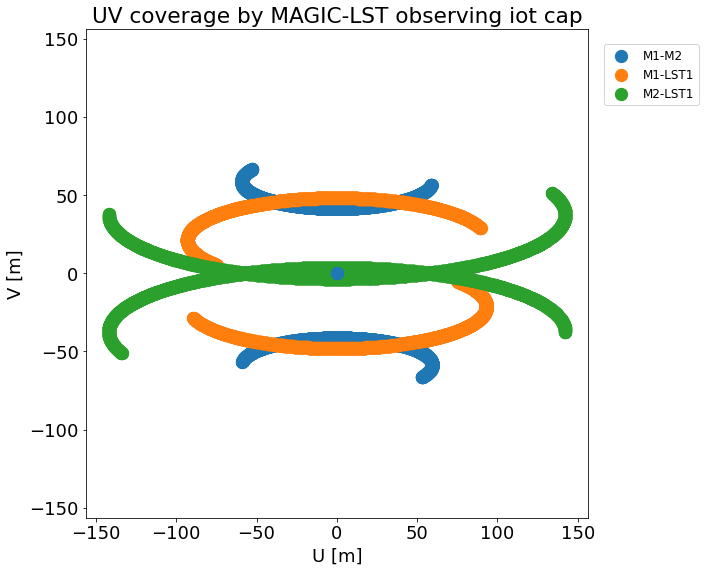

(0.0, 400.0)

In [3]:

import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
from astropy import coordinates as c
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("iot cap", zbc_norm=1., observatory_name="MAGIC-LST")
sim_run.target_skycoord = c.SkyCoord.from_name("iot Cap")
sim_run.stellar_diameter = 1.5 * u.mas
sim_run.target_b_mag = 5.18
print(sim_run.target_b_mag)

times = ['2023-8-31T22:00:00', 
         '2023-8-31T23:00:00', 
         '2023-9-1T00:00:00', 
         '2023-9-1T01:00:00', 
         '2023-9-1T02:00:00', 
         '2023-9-1T03:00:00', 
         ]
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=500*u.min)
# ZBC measurement from Adhara (A-C): 2.316 ± 0.057
sim_run.add_zbc_measurement(2.316/2.316, 0.057/2.316, "M1")
# sim_run.simulate_zbc_observations(time_array, run_duration=600*u.min)

sim_run.plot_v2(set_log_yscale=False)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=False)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
sim_run.f
sim_run.plot_uv()
sim_run.f.get_axes()[0].set_xlim([0, 400])

Check fast rotator UV coverage (gam UMi)
==================

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (230.18215016, 71.83401654)>
Closest star found within the JMDC is:
 -Star ids: HD136726 or --
- Stellar diameter: 2.264


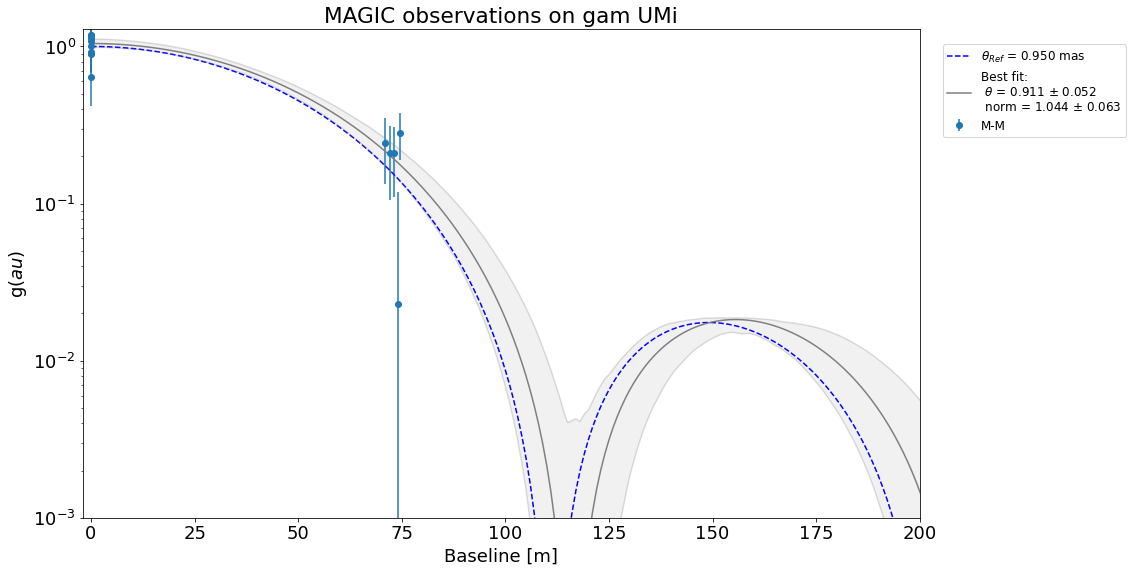

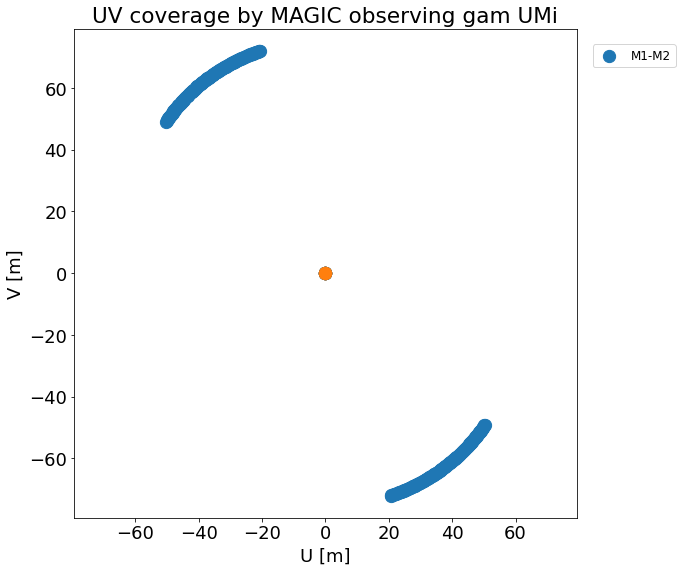

In [17]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("gam UMi", zbc_norm=1., observatory_name="MAGIC")

times = ['2023-07-07T02:30:00', 
         '2023-07-07T03:00:00', 
         '2023-07-07T03:30:00', 
         '2023-07-07T04:00:00', 
         '2023-07-07T04:30:00']
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.stellar_diameter = 0.95 * u.mas


sim_run.simulate_observations(time_array, run_duration=30*u.min)
sim_run.simulate_zbc_observations(time_array, run_duration=30*u.min)
# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
sim_run.f.get_axes()[0].set_xlim([0, 400])
sim_run.f
sim_run.plot_uv()

Check 4LSTs+MAGIC baselines
==========

ERROR:root:The altitude of the source at the time 2021-05-15T02:00:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2021-05-15T03:00:00.000 is just too low.


Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (152.09296244, 11.96720878)>
Closest star found within the JMDC is:
 -Star ids: HD87901 or ALF LEO
- Stellar diameter: 1.33


ERROR:root:The altitude of the source at the time 2021-05-15T04:00:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2021-05-15T02:00:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2021-05-15T03:00:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2021-05-15T04:00:00.000 is just too low.


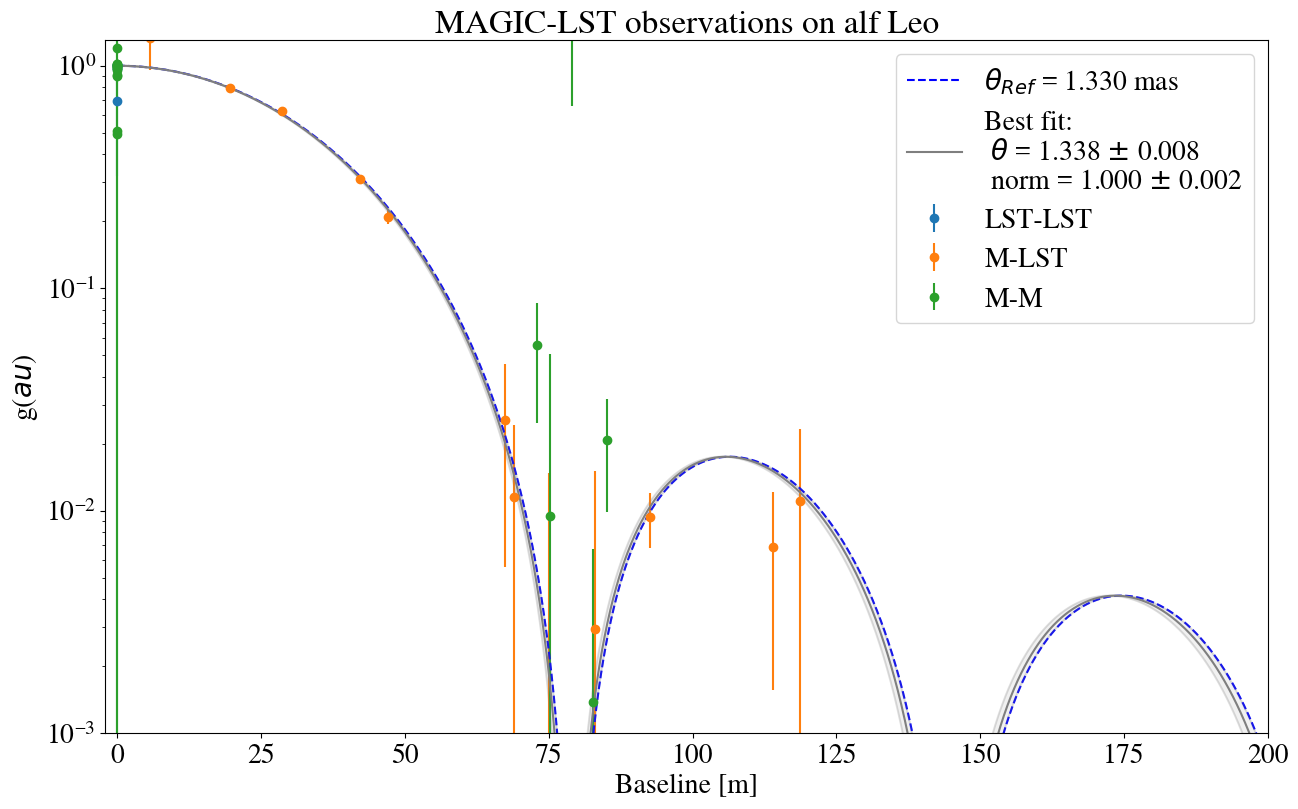

0.005745835516162289

In [8]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("alf Leo", zbc_norm=1., observatory_name="MAGIC-LST", )

times = ['2021-05-14T22:00:00',
         '2021-05-14T23:00:00',
         '2021-05-15T00:10:00',
         '2021-05-15T01:00:00', 
         '2021-05-15T02:00:00', 
         '2021-05-15T03:00:00', 
         '2021-05-15T04:00:00']
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min, ignore_zd=True)
sim_run.simulate_zbc_observations(time_array, run_duration=10*u.min, ignore_zd=True)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']

In [ ]:
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("zet Oph", zbc_norm=1., observatory_name="MAGIC-4LST")

times = ['2021-05-14T22:00:00']
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.simulate_zbc_observations(time_array, run_duration=10*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']